# Time-to-Event Survival Analysis and Early Warning System (EWS) for Silent Churn Using Subspace RBF Kernel PCA

This repository implements an end-to-end survival analysis and preventive **Silent Churn Early Warning System (EWS)** over longitudinal digital financial transaction and daily balance trajectories across a 91-day observation window. Customers rarely abandon an account abruptly; instead, they exhibit progressive behavioral atrophy---falling balance reserves, collapsing weekly transaction cadence, and lengthening recency gaps---weeks prior to formal churn.

### Methodological Architecture

1. **Survival Evaluation Under Right-Censoring:** Standard binary classification metrics misrepresent temporal risk when accounts remain active past the study cutoff. We implement exact Harrell's concordance index (C-index) in $O(n \log n)$ time via a Fenwick tree (`_FenwickTree`), Kaplan-Meier survival schedules, two-sample log-rank tests, and Inverse Probability of Censoring Weighted (IPCW) Brier and Integrated Brier Scores (IBS) across horizons $t \in \{30, 60, 90\}$ days.
2. **High-Throughput Longitudinal Behavioral Engineering:** Anchored at the observation cutoff (`2024-03-31`), consolidated lazy `Polars` scans extract outgoing velocity decay (`active_days_jan`, `active_days_feb`, `active_days_mar`), non-self peer-to-peer inflows, balance drawdown trends (`BAL_TREND_M3_M1`), and `kyc` cohort encodings without temporal leakage.
3. **Zero-Leakage Subspace Landmark RBF Kernel PCA (`N_KPCA_COMP = 8`, `N_KPCA_LANDMARKS = 1500`):** Inside each CV training fold (`tr_i`), up to `24` core behavioral predictors (`kpca_sub_cols`) undergo `_signed_log1p` scaling and stratified landmark `KernelPCA(kernel="rbf", gamma=1/P_sub)`, with out-of-sample projections aligned across folds via unlabeled $8 \times 8$ SVD Procrustes rotation.
4. **Multi-Paradigm Survival Ensemble and Calibration:** Base learners (`LightGBM` across $\{30, 60, 75, 83, 90\}$ days, `CatBoost` at $\{60, 90\}$ days, binary/AFT/Cox `XGBoost`, and bagged `RandomForestClassifier`) feed Level-2 meta-stackers (`L2_LGB_Meta`, `L2_XGB_Cox_Meta`, `L2_RF_Meta`) calibrated monotonically ($S(30) \ge S(60) \ge S(90)$).
5. **Preventive Silent Churn Early Warning System (Section 9):** Combines calibrated forward survival probabilities with three behavioral velocity signals---30-day average balance contraction (`>= 50%`), monthly-to-monthly weekly transaction frequency collapse (`active_days_per_week`), and multi-tier recency inactivity alerts (`TRX_RECENCY_DAYS` at `15d` and `30d`)---to flag at-risk accounts **30+ days in advance** (`ews_risk_alert_dashboard.csv`, `ews_behavioral_trigger_analysis.csv`, `ews_alert_tier_validation.csv`, `ews_silent_churn_dashboard.png`).

## 1. Environment Configuration, Hardware Detection, and Survival Metrics

This section initializes deterministic random seeds, probes available GPU/CPU backends (`CUDA` for `XGBoost` and `CatBoost`), and defines self-contained, exact implementations of survival analysis metrics. To ensure portability across minimal compute environments, `exact_concordance_index_censored`, `exact_ipcw_brier_at_times`, `exact_integrated_brier_score`, `kaplan_meier_table`, and `logrank_test_2sample` are implemented directly in `NumPy` and `SciPy` with an $O(n \log n)$ Fenwick tree for censored concordance evaluation.

In [1]:
import os, sys, gc, glob, math, time, random, warnings, subprocess
from pathlib import Path
from datetime import timedelta, date
import datetime as dt

warnings.filterwarnings("ignore")

def _install_if_missing(pkgs):
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *pkgs],
            check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
        )
    except Exception:
        pass

for mod, pkg in [("polars", "polars"), ("lightgbm", "lightgbm"), ("xgboost", "xgboost")]:
    try:
        __import__(mod)
    except ImportError:
        _install_if_missing([pkg])

import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import xgboost as xgb
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import KernelPCA

try:
    from IPython.display import display as _ipy_display, HTML as _ipy_html
except Exception:
    _ipy_display, _ipy_html = None, None

# Configure unified publication-quality figure styling
plt.rcParams.update({
    "figure.dpi": 135,
    "savefig.dpi": 180,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.85,
    "axes.titlesize": 11.0,
    "axes.titleweight": "semibold",
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#e2e8f0",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
})


def _style_ax(ax, title: str, xlabel: str = "", ylabel: str = "", grid_axis: str = "both"):
    """Apply consistent despined academic styling to a Matplotlib axis."""
    ax.set_title(title, pad=10, color="#0f172a")
    if xlabel:
        ax.set_xlabel(xlabel, color="#334155")
    if ylabel:
        ax.set_ylabel(ylabel, color="#334155")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.35, color="#94a3b8")
    return ax


def display_table(
    df: pd.DataFrame,
    title=None,
    precision: int = 4,
    max_cols_highlight=None,
    min_cols_highlight=None,
):
    """Render a styled Pandas table in notebook environments with clean CLI fallback."""
    if _ipy_display is not None and "ipykernel" in sys.modules:
        if title:
            _ipy_display(_ipy_html(
                f"<h4 style='margin:10px 0 4px 0;font-family:sans-serif;color:#0f172a;'>{title}</h4>"
            ))
        num_cols = df.select_dtypes(include=[np.floating]).columns.tolist()
        fmt_map = {c: f"{{:.{precision}f}}" for c in num_cols}
        styler = (
            df.style
            .format(fmt_map, na_rep="-")
            .hide(axis="index")
            .set_table_styles([
                {"selector": "th", "props": [
                    ("background-color", "#1e293b"), ("color", "#f8fafc"),
                    ("font-weight", "600"), ("font-size", "12px"),
                    ("padding", "6px 10px"), ("text-align", "left"),
                    ("border-bottom", "2px solid #0f172a"),
                ]},
                {"selector": "td", "props": [
                    ("padding", "5px 10px"), ("font-size", "12px"),
                    ("border-bottom", "1px solid #e2e8f0"), ("color", "#1e293b"),
                ]},
                {"selector": "tbody tr:nth-child(even)", "props": [
                    ("background-color", "#f8fafc"),
                ]},
            ])
        )
        if max_cols_highlight:
            valid = [c for c in max_cols_highlight if c in df.columns]
            if valid:
                styler = styler.highlight_max(subset=valid, color="#dcfce7")
        if min_cols_highlight:
            valid = [c for c in min_cols_highlight if c in df.columns]
            if valid:
                styler = styler.highlight_min(subset=valid, color="#dbeafe")
        _ipy_display(styler)
    else:
        if title:
            print(f"\n=== {title} ===")
        print(df.to_string(index=False))


HAS_CATBOOST = False
try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except Exception:
    pass

# Verify actual GPU training availability for gradient-boosted learners
HAS_XGB_CUDA = False
HAS_CB_GPU = False
try:
    _res = subprocess.run(["nvidia-smi"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=False)
    if _res.returncode == 0:
        try:
            _dm = xgb.DMatrix(np.random.randn(16, 4).astype(np.float32), label=np.array([0, 1] * 8))
            xgb.train({"tree_method": "hist", "device": "cuda", "max_depth": 2}, _dm, num_boost_round=2, verbose_eval=False)
            HAS_XGB_CUDA = True
        except Exception:
            pass
        if HAS_CATBOOST:
            try:
                _cb = CatBoostClassifier(iterations=2, depth=2, task_type="GPU", verbose=False)
                _cb.fit(np.random.randn(16, 4), np.array([0, 1] * 8))
                HAS_CB_GPU = True
            except Exception:
                pass
except Exception:
    pass
HAS_CUDA = HAS_XGB_CUDA or HAS_CB_GPU

# Optional external survival libraries paired with exact pure-NumPy analytical fallbacks
HAS_SKSURV = False
try:
    from sksurv.util import Surv as _SksurvSurv
    from sksurv.metrics import (
        concordance_index_censored as _sk_cindex,
        integrated_brier_score as _sk_ibs,
    )
    HAS_SKSURV = True
except Exception:
    pass

HAS_LIFELINES = False
try:
    from lifelines.statistics import logrank_test as _lifelines_logrank
    HAS_LIFELINES = True
except Exception:
    pass


class _SurvFallback:
    """Minimal structured survival array fallback matching sksurv.util.Surv.from_arrays."""
    @staticmethod
    def from_arrays(event, time):
        ev = np.asarray(event, dtype=bool)
        tm = np.asarray(time, dtype=float)
        return np.rec.fromarrays([ev, tm], names="event,time")

Surv = _SksurvSurv if HAS_SKSURV else _SurvFallback


class _FenwickTree:
    """1-indexed Binary Indexed Tree enabling O(N log N) censored concordance updates."""
    __slots__ = ("tree", "n")

    def __init__(self, n: int):
        self.n = n
        self.tree = np.zeros(n + 1, dtype=np.int64)

    def add(self, idx: int, val: int = 1):
        i = idx + 1
        n = self.n
        tree = self.tree
        while i <= n:
            tree[i] += val
            i += i & -i

    def prefix_sum(self, idx: int) -> int:
        if idx < 0:
            return 0
        i = idx + 1
        s = 0
        tree = self.tree
        while i > 0:
            s += tree[i]
            i -= i & -i
        return int(s)


def exact_concordance_index_censored(event_indicator, event_time, estimate):
    """Compute exact Harrell's C-index under right-censoring in O(N log N) time."""
    event = np.asarray(event_indicator, dtype=bool)
    time_arr = np.asarray(event_time, dtype=float)
    risk = np.asarray(estimate, dtype=float)

    n = len(time_arr)
    if n == 0 or event.sum() == 0:
        return (0.5, 0, 0, 0, 0)

    _, risk_ranks = np.unique(risk, return_inverse=True)
    m = int(risk_ranks.max()) + 1

    # Process descending survival times so only subjects strictly surviving longer are active in the Fenwick tree
    order = np.lexsort((event.astype(np.int8), -time_arr))
    sorted_time = time_arr[order]
    sorted_event = event[order]
    sorted_rank = risk_ranks[order]

    bit = _FenwickTree(m)
    total_added = 0
    concordant = discordant = tied_risk = tied_time = 0

    idx = 0
    while idx < n:
        cur_t = sorted_time[idx]
        j = idx
        while j < n and sorted_time[j] == cur_t:
            j += 1
        block_ev = sorted_event[idx:j]
        block_rk = sorted_rank[idx:j]

        cens_mask = ~block_ev
        for rk in block_rk[cens_mask]:
            bit.add(int(rk), 1)
            total_added += 1

        ev_rks = block_rk[block_ev]
        n_ev = len(ev_rks)
        if n_ev > 1:
            tied_time += n_ev * (n_ev - 1) // 2

        for rk in ev_rks:
            rk_i = int(rk)
            conc = bit.prefix_sum(rk_i - 1)
            leq = bit.prefix_sum(rk_i)
            tr = leq - conc
            disc = total_added - leq
            concordant += conc
            tied_risk += tr
            discordant += disc

        for rk in ev_rks:
            bit.add(int(rk), 1)
            total_added += 1
        idx = j

    denom = concordant + discordant + tied_risk
    c_idx = (concordant + 0.5 * tied_risk) / denom if denom > 0 else 0.5
    return (float(c_idx), int(concordant), int(discordant), int(tied_risk), int(tied_time))


def _km_censoring_weights(train_event, train_time):
    """Estimate Kaplan-Meier censoring survival function G(t) for IPCW weighting."""
    ev_c = ~np.asarray(train_event, dtype=bool)
    tm = np.asarray(train_time, dtype=float)
    order = np.argsort(tm)
    tm_s, ev_s = tm[order], ev_c[order]
    uniq_t, idx_start, counts = np.unique(tm_s, return_index=True, return_counts=True)
    d_c = np.add.reduceat(ev_s.astype(np.int64), idx_start)
    at_risk = len(tm_s) - np.concatenate(([0], np.cumsum(counts[:-1])))
    with np.errstate(divide="ignore", invalid="ignore"):
        surv_step = np.where(at_risk > 0, 1.0 - d_c / at_risk, 1.0)
    return uniq_t, np.cumprod(surv_step)


def _eval_step_right_continuous(times_eval, km_times, km_vals):
    """Evaluate a right-continuous step function at arbitrary time points."""
    idx = np.searchsorted(km_times, times_eval, side="right") - 1
    out = np.ones_like(times_eval, dtype=float)
    valid = idx >= 0
    out[valid] = km_vals[idx[valid]]
    return out


def exact_ipcw_brier_at_times(y_train, y_test, estimate, times):
    """Compute exact IPCW Brier Scores at each horizon and trapezoidal Integrated Brier Score."""
    ev_tr = np.asarray(y_train["event"], dtype=bool)
    tm_tr = np.asarray(y_train["time"], dtype=float)
    ev_te = np.asarray(y_test["event"], dtype=bool)
    tm_te = np.asarray(y_test["time"], dtype=float)
    surv_pred = np.asarray(estimate, dtype=float)
    times = np.asarray(times, dtype=float)

    km_t, G_vals = _km_censoring_weights(ev_tr, tm_tr)
    G_horizon = np.clip(_eval_step_right_continuous(times, km_t, G_vals), 1e-8, 1.0)
    # Left-limit G(T_i-) required for inverse-probability weighting of uncensored failures
    G_subj_minus = np.clip(_eval_step_right_continuous(tm_te - 1e-9, km_t, G_vals), 1e-8, 1.0)

    brier_scores = np.zeros(len(times), dtype=float)
    for k, t in enumerate(times):
        s_k = surv_pred[:, k]
        is_dead = (tm_te <= t) & ev_te
        is_alive = tm_te > t
        contrib = np.zeros(len(tm_te), dtype=float)
        contrib[is_dead] = ((0.0 - s_k[is_dead]) ** 2) / G_subj_minus[is_dead]
        contrib[is_alive] = ((1.0 - s_k[is_alive]) ** 2) / G_horizon[k]
        brier_scores[k] = contrib.mean()

    if len(times) == 1:
        ibs_val = float(brier_scores[0])
    else:
        trapz_fn = getattr(np, "trapezoid", None) or np.trapz
        ibs_val = float(trapz_fn(brier_scores, times) / (times[-1] - times[0]))
    return {int(t): float(b) for t, b in zip(times, brier_scores)}, ibs_val


def exact_integrated_brier_score(y_train, y_test, estimate, times):
    """Return exact IPCW Integrated Brier Score over the specified horizon grid."""
    _, ibs_val = exact_ipcw_brier_at_times(y_train, y_test, estimate, times)
    return ibs_val


def concordance_index_censored(event_indicator, event_time, estimate):
    if HAS_SKSURV:
        return _sk_cindex(event_indicator, event_time, estimate)
    return exact_concordance_index_censored(event_indicator, event_time, estimate)


def integrated_brier_score(y_train, y_test, estimate, times):
    if HAS_SKSURV:
        try:
            return _sk_ibs(y_train, y_test, estimate, times)
        except Exception:
            pass
    return exact_integrated_brier_score(y_train, y_test, estimate, times)


def kaplan_meier_table(durations, events, max_day=91):
    """Construct daily Kaplan-Meier survival schedule, Greenwood 95% CIs, and smoothed hazard."""
    dur = np.asarray(durations, dtype=np.int64)
    ev = np.asarray(events, dtype=np.int64)
    rows = []
    s, greenwood_sum, cum_haz = 1.0, 0.0, 0.0
    for d in range(0, int(max_day) + 1):
        at_risk = int((dur >= d).sum())
        d_events = int(((dur == d) & (ev == 1)).sum())
        d_cens = int(((dur == d) & (ev == 0)).sum())
        if at_risk > 0 and d_events > 0:
            haz = d_events / at_risk
            s *= (1.0 - haz)
            cum_haz += haz
            denom = at_risk * (at_risk - d_events)
            if denom > 0:
                greenwood_sum += d_events / denom
        else:
            haz = 0.0
        se = s * math.sqrt(greenwood_sum) if greenwood_sum > 0 else 0.0
        rows.append({
            "day": int(d), "at_risk": at_risk, "events": d_events, "censored": d_cens,
            "hazard_rate": haz, "hazard_pct": haz * 100.0, "cum_hazard": cum_haz,
            "survival": s, "ci_lower": max(0.0, s - 1.96 * se),
            "ci_upper": min(1.0, s + 1.96 * se), "churn_cdf": 1.0 - s,
        })
    df = pd.DataFrame(rows)
    df["hazard_7d_smooth_pct"] = df["hazard_pct"].rolling(7, center=True, min_periods=1).mean()
    return df


def logrank_test_2sample(dur_a, ev_a, dur_b, ev_b):
    """Perform Mantel-Haenszel two-sample log-rank test under right-censoring."""
    if HAS_LIFELINES:
        try:
            res = _lifelines_logrank(dur_a, dur_b, event_observed_A=ev_a, event_observed_B=ev_b)
            return float(res.test_statistic), float(res.p_value)
        except Exception:
            pass
    da, ea = np.asarray(dur_a, dtype=np.int64), np.asarray(ev_a, dtype=np.int64)
    db, eb = np.asarray(dur_b, dtype=np.int64), np.asarray(ev_b, dtype=np.int64)
    times = np.unique(np.concatenate([da[ea == 1], db[eb == 1]]))
    if len(times) == 0:
        return 0.0, 1.0
    obs_a = exp_a = var_t = 0.0
    for t in times:
        n1, n2 = float((da >= t).sum()), float((db >= t).sum())
        n = n1 + n2
        if n <= 1:
            continue
        o1, o2 = float(((da == t) & (ea == 1)).sum()), float(((db == t) & (eb == 1)).sum())
        o = o1 + o2
        obs_a += o1
        exp_a += n1 * (o / n)
        var_t += (n1 * n2 * o * (n - o)) / (n * n * (n - 1.0))
    if var_t <= 0:
        return 0.0, 1.0
    chi2_stat = ((obs_a - exp_a) ** 2) / var_t
    return float(chi2_stat), float(stats.chi2.sf(chi2_stat, df=1))


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

env_summary_df = pd.DataFrame([
    {"Component": "Polars / LightGBM / XGBoost", "Status": f"{pl.__version__} / {lgb.__version__} / {xgb.__version__}"},
    {"Component": "CatBoost Backend", "Status": f"Enabled ({'GPU' if HAS_CB_GPU else 'CPU'})" if HAS_CATBOOST else "Unavailable (LGBM fallback)"},
    {"Component": "XGBoost Compute Device", "Status": "CUDA GPU" if HAS_XGB_CUDA else "CPU Hist"},
    {"Component": "Survival Metric Implementation", "Status": f"sksurv={'native' if HAS_SKSURV else 'exact NumPy'}, lifelines={'native' if HAS_LIFELINES else 'exact NumPy'}"},
])
display_table(env_summary_df, title="Compute Environment and Library Configuration")

Component,Status
Polars / LightGBM / XGBoost,1.35.2 / 4.6.0 / 3.4.1
CatBoost Backend,Enabled (GPU)
XGBoost Compute Device,CUDA GPU
Survival Metric Implementation,"sksurv=exact NumPy, lifelines=exact NumPy"


## 2. Cohort Data Ingestion and Temporal Observation Windows

We load the labeled cohort (`train_labels.csv`), holdout accounts (`test.csv`), demographic records (`kyc.parquet`), and lazy `Polars` scans over partitioned transaction and day-end balance tables. All lookback windows (`D_3` through `D_90`) are anchored strictly to the fixed observation reference date (`2024-03-31`) to prevent temporal leakage across active and censored accounts.

In [2]:
LOCAL_DIR = r"d:\Survival Analysis"

def resolve_data_dir() -> Path:
    for p in Path("/kaggle/input").rglob("train_labels.csv"):
        return p.parent
    local_p = Path(LOCAL_DIR)
    if (local_p / "train_labels.csv").exists():
        return local_p
    raise FileNotFoundError("train_labels.csv not found in /kaggle/input or LOCAL_DIR.")

COMP = resolve_data_dir()
OUTPUT_DIR = Path("/kaggle/working/survival_outputs") if Path("/kaggle/working").exists() else (COMP / "survival_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_labels = pd.read_csv(COMP / "train_labels.csv")
test_df      = pd.read_csv(COMP / "test.csv")
kyc          = pl.read_parquet(COMP / "kyc.parquet")

# Anchor all multi-scale lookback windows strictly to the observation boundary to prevent temporal leakage
OBS_DATE = date(2024, 3, 31)
D_3  = OBS_DATE - timedelta(days=3)
D_7  = OBS_DATE - timedelta(days=7)
D_14 = OBS_DATE - timedelta(days=14)
D_28 = OBS_DATE - timedelta(days=28)
D_30 = OBS_DATE - timedelta(days=30)
D_60 = OBS_DATE - timedelta(days=60)
D_90 = OBS_DATE - timedelta(days=90)

TXN_FILES = sorted(str(f) for f in (COMP / "transactions").glob("*.parquet"))
BAL_FILES = sorted(str(f) for f in (COMP / "dayend_balance").glob("*.parquet"))
txn_lf = pl.scan_parquet(TXN_FILES)
bal_lf = pl.scan_parquet(BAL_FILES)

USE_SAMPLE  = False
SAMPLE_FRAC = 0.15

all_train_ids = train_labels["ACCOUNT_ID"].tolist()
all_test_ids  = test_df["ACCOUNT_ID"].tolist()
if USE_SAMPLE:
    SAMPLE_TRAIN_IDS = set(random.sample(all_train_ids, int(len(all_train_ids) * SAMPLE_FRAC)))
    ACTIVE_IDS = list(SAMPLE_TRAIN_IDS) + all_test_ids
else:
    SAMPLE_TRAIN_IDS = set(all_train_ids)
    ACTIVE_IDS = list(set(all_train_ids) | set(all_test_ids))
all_ids_needed = ACTIVE_IDS

churn_rate = float(train_labels["EVENT_FLAG"].mean())
ingest_summary_df = pd.DataFrame([
    {"Dataset Artifact": "train_labels.csv", "Rows": f"{len(train_labels):,}", "Columns": train_labels.shape[1], "Notes": f"{train_labels['EVENT_FLAG'].sum():,} churn events ({churn_rate * 100:.2f}% rate)"},
    {"Dataset Artifact": "test.csv", "Rows": f"{len(test_df):,}", "Columns": test_df.shape[1], "Notes": "Holdout evaluation accounts"},
    {"Dataset Artifact": "kyc.parquet", "Rows": f"{kyc.shape[0]:,}", "Columns": kyc.shape[1], "Notes": "Account demographics and opening dates"},
    {"Dataset Artifact": "transactions / dayend_balance", "Rows": "Lazy Parquet", "Columns": f"{len(TXN_FILES)} / {len(BAL_FILES)} files", "Notes": f"Reference cutoff={OBS_DATE} | Active IDs={len(ACTIVE_IDS):,}"},
])
display_table(ingest_summary_df, title="Data Ingestion and Observation Window Summary")

Dataset Artifact,Rows,Columns,Notes
train_labels.csv,"595,000",3,"30,994 churn events (5.21% rate)"
test.csv,"255,000",1,Holdout evaluation accounts
kyc.parquet,"1,000,000",5,Account demographics and opening dates
transactions / dayend_balance,Lazy Parquet,3 / 3 files,"Reference cutoff=2024-03-31 | Active IDs=850,000"


## 3. Empirical Hazard Profiling Across the 91-Day Observation Window

Before feature construction, we compute the daily Kaplan-Meier survival curve and empirical hazard schedule (`daily_hazard_table_91d.csv`) over `DURATION_DAYS`. Inspecting hazard concentration across discrete time intervals clarifies whether churn events cluster during early onboarding, mid-period dormancy, or late-horizon decay.

Total Accounts,Churned,Censored,Event Rate (%),P25 / Median / P75 Day,Mean Churn Day,Peak Churn Day
"595,000","30,994","564,006",5.21,76 / 83 / 88,79.98,"Day 90 (3,565 events, 0.6281%)"


Observation Window,Churn Events,Share of Total Churns (%),Mean Daily Hazard (%),Period-End KM Survival (%)
Early Horizon (0-30d),286,0.9200,0.0016,99.9500
Mid Horizon (31-60d),"1,593",5.1400,0.0089,99.6800
Late Horizon (61-91d),"29,115",93.9400,0.1621,94.7900


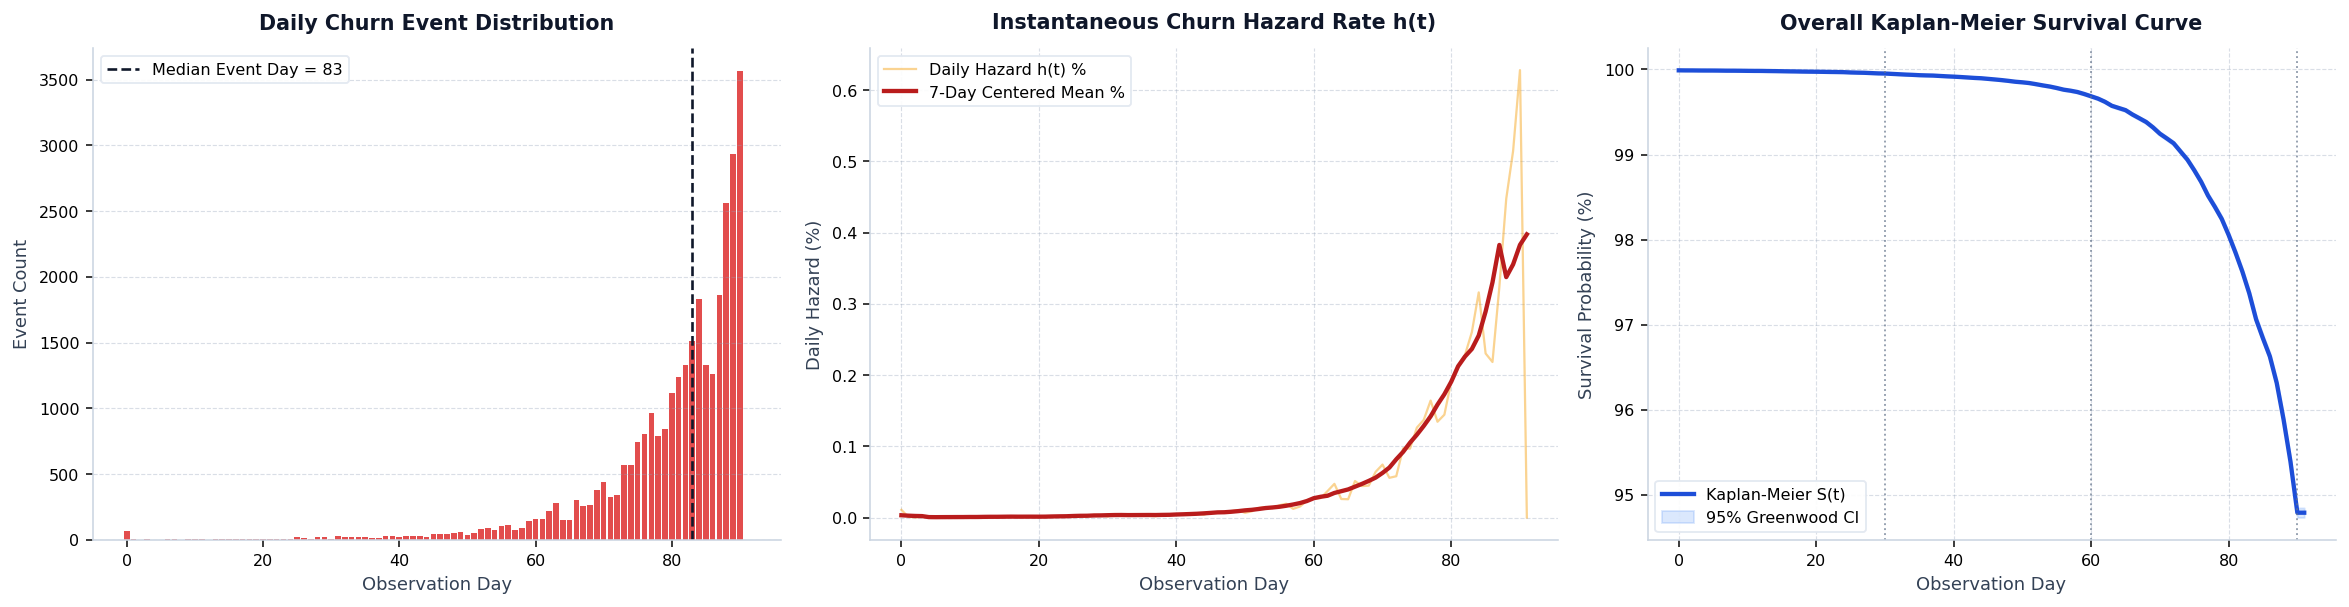

In [3]:
dur_all = train_labels["DURATION_DAYS"].to_numpy(dtype=np.int64)
ev_all  = train_labels["EVENT_FLAG"].to_numpy(dtype=np.int64)
max_day = int(dur_all.max())

km_overall = kaplan_meier_table(dur_all, ev_all, max_day=max_day)
km_overall.to_csv(OUTPUT_DIR / "daily_hazard_table_91d.csv", index=False)

churned_days = dur_all[ev_all == 1]
peak_row = km_overall.loc[km_overall["events"].idxmax()]

timing_overview_df = pd.DataFrame([{
    "Total Accounts": f"{len(dur_all):,}",
    "Churned": f"{len(churned_days):,}",
    "Censored": f"{(ev_all == 0).sum():,}",
    "Event Rate (%)": round(float(ev_all.mean() * 100.0), 2),
    "P25 / Median / P75 Day": f"{np.percentile(churned_days, 25):.0f} / {np.median(churned_days):.0f} / {np.percentile(churned_days, 75):.0f}",
    "Mean Churn Day": round(float(churned_days.mean()), 2),
    "Peak Churn Day": f"Day {int(peak_row['day'])} ({int(peak_row['events']):,} events, {peak_row['hazard_pct']:.4f}%)",
}])
display_table(timing_overview_df, title="Overall 91-Day Cohort Survival Summary", precision=2)

window_rows = []
for lo, hi, label in [(0, 30, "Early Horizon (0-30d)"), (31, 60, "Mid Horizon (31-60d)"), (61, max_day, f"Late Horizon (61-{max_day}d)")]:
    sub = km_overall[(km_overall["day"] >= lo) & (km_overall["day"] <= hi)]
    tot_ev = int(sub["events"].sum())
    end_surv = float(sub["survival"].iloc[-1] * 100.0) if len(sub) else 100.0
    window_rows.append({
        "Observation Window": label,
        "Churn Events": f"{tot_ev:,}",
        "Share of Total Churns (%)": round(100.0 * tot_ev / max(1, len(churned_days)), 2),
        "Mean Daily Hazard (%)": round(float(sub["hazard_pct"].mean()), 4),
        "Period-End KM Survival (%)": round(end_surv, 2),
    })
window_hazard_df = pd.DataFrame(window_rows)
display_table(window_hazard_df, title="Discrete Horizon Churn Concentration and Empirical Hazard", precision=4)

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.6))
axes[0].bar(km_overall["day"], km_overall["events"], color="#dc2626", alpha=0.82, width=0.82)
axes[0].axvline(np.median(churned_days), color="#0f172a", linestyle="--", lw=1.4, label=f"Median Event Day = {np.median(churned_days):.0f}")
_style_ax(axes[0], "Daily Churn Event Distribution", "Observation Day", "Event Count", grid_axis="y")
axes[0].legend(loc="upper left", fontsize=8.5)

axes[1].plot(km_overall["day"], km_overall["hazard_pct"], color="#f59e0b", alpha=0.45, lw=1.2, label="Daily Hazard h(t) %")
axes[1].plot(km_overall["day"], km_overall["hazard_7d_smooth_pct"], color="#b91c1c", lw=2.3, label="7-Day Centered Mean %")
_style_ax(axes[1], "Instantaneous Churn Hazard Rate h(t)", "Observation Day", "Daily Hazard (%)")
axes[1].legend(loc="upper left", fontsize=8.5)

axes[2].plot(km_overall["day"], km_overall["survival"] * 100.0, color="#1d4ed8", lw=2.3, label="Kaplan-Meier S(t)")
axes[2].fill_between(km_overall["day"], km_overall["ci_lower"] * 100.0, km_overall["ci_upper"] * 100.0, color="#3b82f6", alpha=0.18, label="95% Greenwood CI")
for mark_d in [30, 60, min(90, max_day)]:
    axes[2].axvline(mark_d, color="#64748b", linestyle=":", lw=1.0, alpha=0.7)
_style_ax(axes[2], "Overall Kaplan-Meier Survival Curve", "Observation Day", "Survival Probability (%)")
axes[2].legend(loc="lower left", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "churn_timing_and_hazard_91d.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Non-Parametric Cohort Stratification: Tenure, Gender, and Geography

We evaluate heterogeneity across demographic and tenure segments derived from `kyc` records relative to `2024-03-31`. Accounts are partitioned by median tenure into newer and older cohorts, compared statistically using the two-sample log-rank test (`chi2`, p-value), and summarized via 30-, 60-, and 90-day Kaplan-Meier survival probabilities across `GENDER`, `REGION`, and `ACCOUNT_TYPE`.

Comparison,Newer Cohort N,Older Cohort N,Chi-Square Statistic,Log-Rank p-value
"Median Tenure Split (1,434 days)","297,973","297,027",4.77,2.891e-02


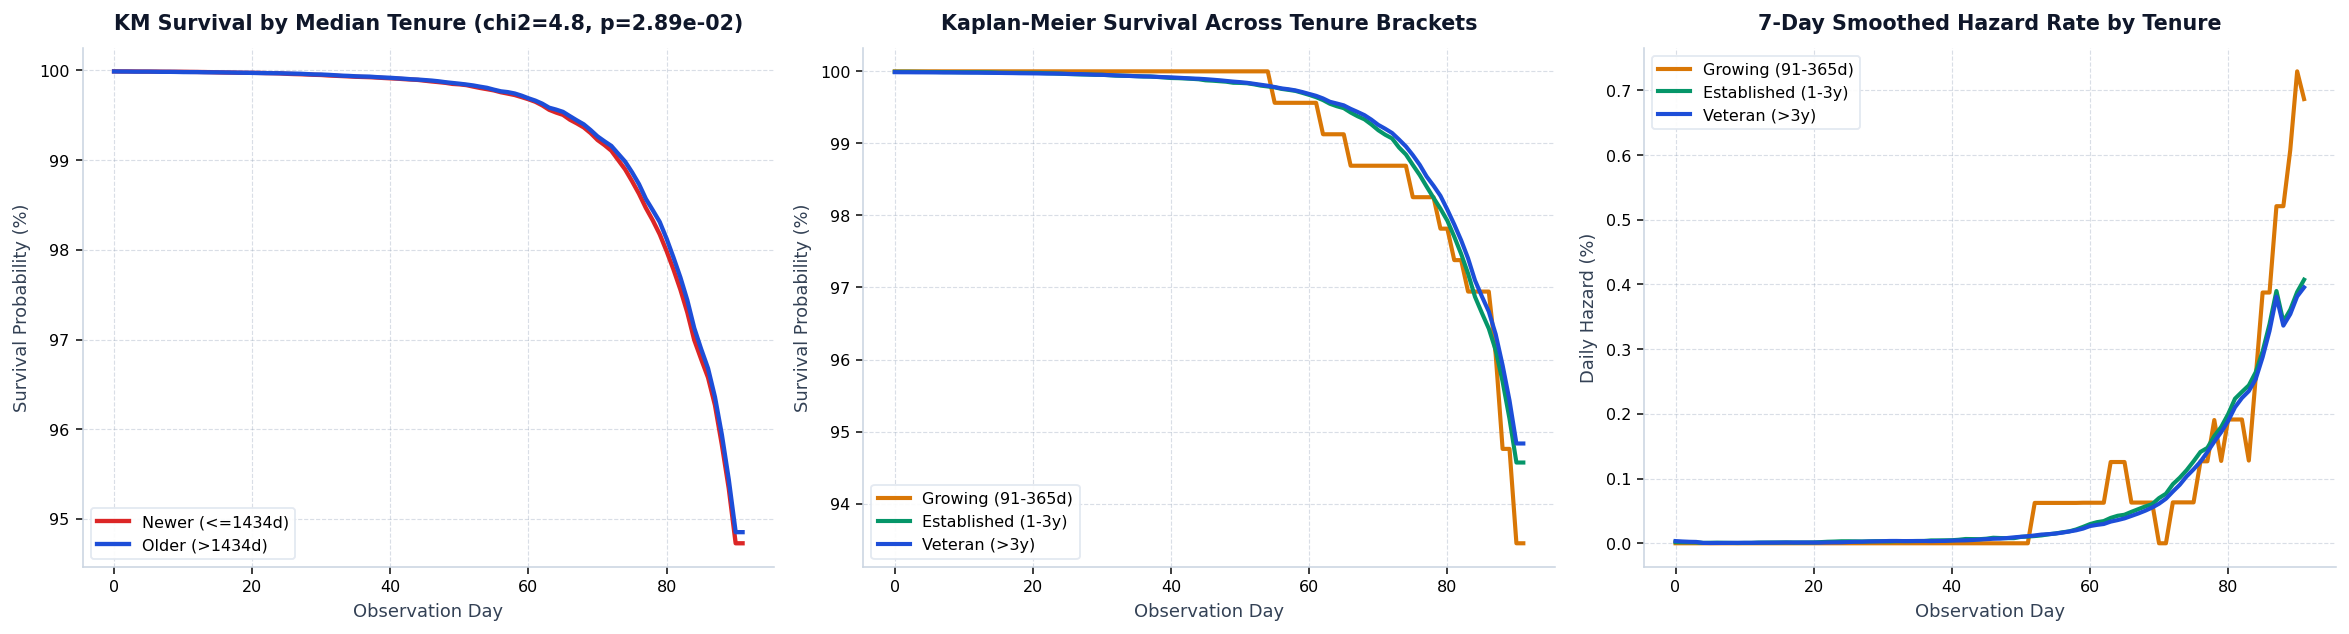

Segment Group,Cohort,Accounts,Churn Events,Churn Rate (%),Hazard / 1k Person-Days,KM 90d Survival (%)
Tenure,Growing (91-365d),229,15,6.550,0.725,93.450
Tenure,Established (1-3y),97303,5283,5.429,0.601,94.571
Tenure,Veteran (>3y),497468,25696,5.165,0.571,94.835
Region,Barishal,41459,2181,5.261,0.582,94.739
Region,Chattogram,106808,5506,5.155,0.570,94.845
Region,Dhaka,208593,11006,5.276,0.584,94.724
Region,Khulna,53230,2749,5.164,0.571,94.836
Region,Mymensingh,35603,1827,5.132,0.568,94.868
Region,Rajshahi,59724,3112,5.211,0.576,94.789
Region,Rangpur,30052,1513,5.035,0.557,94.965


14877

In [4]:
kyc_pd = (
    kyc.with_columns([
        (pl.lit(OBS_DATE) - pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date)).dt.total_days().cast(pl.Int32).alias("account_tenure_days")
    ])
    .select(["ACCOUNT_ID", "account_tenure_days", "GENDER", "REGION", "ACCOUNT_TYPE"])
    .to_pandas()
)
surv_df = train_labels.merge(kyc_pd, on="ACCOUNT_ID", how="left")
surv_df["account_tenure_days"] = surv_df["account_tenure_days"].fillna(surv_df["account_tenure_days"].median())

bins = [-10**9, 90, 365, 1095, 10**9]
labels_4 = ["New (<=90d)", "Growing (91-365d)", "Established (1-3y)", "Veteran (>3y)"]
surv_df["TENURE_SEGMENT"] = pd.cut(surv_df["account_tenure_days"], bins=bins, labels=labels_4)

split_days = int(surv_df["account_tenure_days"].median())
g_new = f"Newer (<={split_days}d)"
g_old = f"Older (>{split_days}d)"
surv_df["CUSTOMER_AGE_GROUP"] = np.where(surv_df["account_tenure_days"] <= split_days, g_new, g_old)
sub_new, sub_old = surv_df[surv_df["CUSTOMER_AGE_GROUP"] == g_new], surv_df[surv_df["CUSTOMER_AGE_GROUP"] == g_old]

km_new = kaplan_meier_table(sub_new["DURATION_DAYS"].values, sub_new["EVENT_FLAG"].values, max_day=max_day)
km_old = kaplan_meier_table(sub_old["DURATION_DAYS"].values, sub_old["EVENT_FLAG"].values, max_day=max_day)
chi2_no, pval_no = logrank_test_2sample(
    sub_new["DURATION_DAYS"].values, sub_new["EVENT_FLAG"].values,
    sub_old["DURATION_DAYS"].values, sub_old["EVENT_FLAG"].values
)

logrank_df = pd.DataFrame([{
    "Comparison": f"Median Tenure Split ({split_days:,} days)",
    "Newer Cohort N": f"{len(sub_new):,}",
    "Older Cohort N": f"{len(sub_old):,}",
    "Chi-Square Statistic": round(chi2_no, 2),
    "Log-Rank p-value": f"{pval_no:.3e}",
}])
display_table(logrank_df, title="Two-Sample Log-Rank Test Across Tenure Cohorts", precision=2)

km_tenure, seg_rows = {}, []
for seg in labels_4:
    sub = surv_df[surv_df["TENURE_SEGMENT"] == seg]
    if len(sub) < 10:
        continue
    kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
    km_tenure[seg] = kt
    seg_rows.append({
        "Segment Group": "Tenure",
        "Cohort": seg,
        "Accounts": len(sub),
        "Churn Events": int(sub["EVENT_FLAG"].sum()),
        "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
        "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
        "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
    })

fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.8))
for lbl, kt, col in [(g_new, km_new, "#dc2626"), (g_old, km_old, "#1d4ed8")]:
    axes[0].plot(kt["day"], kt["survival"] * 100.0, color=col, lw=2.3, label=lbl)
_style_ax(axes[0], f"KM Survival by Median Tenure (chi2={chi2_no:.1f}, p={pval_no:.2e})", "Observation Day", "Survival Probability (%)")
axes[0].legend(loc="lower left", fontsize=8.5)

palette_4 = ["#dc2626", "#d97706", "#059669", "#1d4ed8"]
for seg, col in zip(labels_4, palette_4):
    if seg in km_tenure:
        axes[1].plot(km_tenure[seg]["day"], km_tenure[seg]["survival"] * 100.0, color=col, lw=2.2, label=seg)
        axes[2].plot(km_tenure[seg]["day"], km_tenure[seg]["hazard_7d_smooth_pct"], color=col, lw=2.2, label=seg)
_style_ax(axes[1], "Kaplan-Meier Survival Across Tenure Brackets", "Observation Day", "Survival Probability (%)")
axes[1].legend(loc="lower left", fontsize=8.5)
_style_ax(axes[2], "7-Day Smoothed Hazard Rate by Tenure", "Observation Day", "Daily Hazard (%)")
axes[2].legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "km_new_vs_old_customers.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

for col_name, grp_label in [("REGION", "Region"), ("GENDER", "Gender")]:
    grp_df = surv_df.assign(**{col_name: surv_df[col_name].fillna("UNKNOWN").astype(str)})
    for val, sub in grp_df.groupby(col_name):
        if len(sub) < 50:
            continue
        kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
        seg_rows.append({
            "Segment Group": grp_label,
            "Cohort": str(val),
            "Accounts": len(sub),
            "Churn Events": int(sub["EVENT_FLAG"].sum()),
            "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
            "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
            "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
        })

kyc_seg_summary = pd.DataFrame(seg_rows)
kyc_seg_summary.to_csv(OUTPUT_DIR / "kyc_segment_hazard_summary.csv", index=False)
display_table(kyc_seg_summary, title="Kaplan-Meier Survival and Hazard Summary Across KYC Cohorts", precision=3)
del surv_df, kyc_pd; gc.collect()

## 5. Longitudinal Transaction Feature Engineering via Consolidated `Polars` Scans

Naive event aggregation often requires repeated passes over multi-million-row transaction logs and omits incoming counterparty behavior. Instead, we consolidate outgoing (`SRC_ACCOUNT`) and non-self incoming (`DST_ACCOUNT`) aggregations into two single-pass lazy `Polars` pipelines:

* **Recency and Inter-Transaction Cadence:** Days since last overall activity, transaction-type-specific recency (`CashIn`, `CashOut`, `BillPay`, `MerchantPay`), and empirical inter-event gap dispersion (`gap_mean`, `gap_median`, `gap_std`).
* **Multi-Horizon Intensity and Momentum:** Cumulative counts, spend quantiles (`p25`, `median`, `p75`, `p90`), micro-transaction shares, monthly trajectory splits (`cnt_jan`, `cnt_feb`, `cnt_mar`), and weekly linear activity slopes (`txn_weekly_slope`).
* **Network Diversity and Peer-to-Peer Inflow:** Unique counterparty, biller, and merchant counts, counterparty concentration indices, and incoming transfer volumes excluding self-transfers.

In [5]:
t0 = time.time()

# Consolidate outgoing transaction aggregations in a single lazy scan bounded by OBS_DATE
txn_src = (
    txn_lf
    .filter(pl.col("SRC_ACCOUNT").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("TRX_DATETIME").str.slice(0, 10).str.to_date("%Y-%m-%d").alias("_TXN_DATE"),
        pl.col("TRX_DATETIME").str.slice(11, 2).cast(pl.Int8, strict=False).alias("_HR"),
        pl.col("TRX_AMT").cast(pl.Float32).alias("_AMT"),
    ])
    .filter(pl.col("_TXN_DATE") <= OBS_DATE)
)

def _win_mask(start_dt):
    return pl.col("_TXN_DATE") >= pl.lit(start_dt)

def _range_mask(start_dt, end_dt):
    return (pl.col("_TXN_DATE") >= pl.lit(start_dt)) & (pl.col("_TXN_DATE") < pl.lit(end_dt))

src_agg = (
    txn_src.group_by("SRC_ACCOUNT").agg([
        pl.len().alias("txn_count_all"),
        _win_mask(D_3).sum().cast(pl.Int32).alias("txn_count_3d"),
        _win_mask(D_7).sum().cast(pl.Int32).alias("txn_count_7d"),
        _win_mask(D_14).sum().cast(pl.Int32).alias("txn_count_14d"),
        _range_mask(D_28, D_14).sum().cast(pl.Int32).alias("txn_count_prev14d"),
        _win_mask(D_30).sum().cast(pl.Int32).alias("txn_count_30d"),
        _range_mask(D_60, D_30).sum().cast(pl.Int32).alias("cnt_30_60"),
        _range_mask(D_90, D_60).sum().cast(pl.Int32).alias("cnt_60_90"),
        _win_mask(D_60).sum().cast(pl.Int32).alias("txn_count_60d"),
        _win_mask(D_90).sum().cast(pl.Int32).alias("txn_count_90d"),

        (pl.col("_TXN_DATE").dt.month() == 1).sum().cast(pl.Int32).alias("cnt_jan"),
        (pl.col("_TXN_DATE").dt.month() == 2).sum().cast(pl.Int32).alias("cnt_feb"),
        (pl.col("_TXN_DATE").dt.month() == 3).sum().cast(pl.Int32).alias("cnt_mar"),

        pl.col("_TXN_DATE").n_unique().cast(pl.Int16).alias("active_days_all"),
        pl.col("_TXN_DATE").filter(_win_mask(D_7)).n_unique().cast(pl.Int16).alias("active_days_7d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_14)).n_unique().cast(pl.Int16).alias("active_days_14d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_30)).n_unique().cast(pl.Int16).alias("active_days_30d"),
        pl.col("_TXN_DATE").filter(_win_mask(D_60)).n_unique().cast(pl.Int16).alias("active_days_60d"),
        pl.col("_TXN_DATE").filter(pl.col("_TXN_DATE").dt.month() == 1).n_unique().cast(pl.Int16).alias("active_days_jan"),
        pl.col("_TXN_DATE").filter(pl.col("_TXN_DATE").dt.month() == 2).n_unique().cast(pl.Int16).alias("active_days_feb"),
        pl.col("_TXN_DATE").filter(pl.col("_TXN_DATE").dt.month() == 3).n_unique().cast(pl.Int16).alias("active_days_mar"),

        pl.col("_TXN_DATE").max().alias("_last_txn_date"),
        pl.col("_TXN_DATE").min().alias("_first_txn_date"),

        pl.col("_AMT").sum().alias("txn_amount_sum_all"),
        pl.col("_AMT").mean().alias("txn_amount_mean_all"),
        pl.col("_AMT").std().alias("txn_amount_std_all"),
        pl.col("_AMT").min().alias("txn_amount_min_all"),
        pl.col("_AMT").quantile(0.25).alias("txn_amount_p25_all"),
        pl.col("_AMT").median().alias("txn_amount_median_all"),
        pl.col("_AMT").quantile(0.75).alias("txn_amount_p75_all"),
        pl.col("_AMT").quantile(0.90).alias("txn_amount_p90_all"),
        pl.col("_AMT").max().alias("txn_amount_max_all"),
        pl.col("_AMT").filter(_win_mask(D_7)).sum().alias("txn_sum_7d"),
        pl.col("_AMT").filter(_win_mask(D_14)).sum().alias("txn_sum_14d"),
        pl.col("_AMT").filter(_win_mask(D_30)).sum().alias("txn_sum_30d"),
        pl.col("_AMT").filter(_win_mask(D_30)).mean().alias("txn_mean_30d"),
        pl.col("_AMT").filter(_win_mask(D_30)).std().alias("txn_std_30d"),
        (pl.col("_AMT") < 100.0).mean().alias("pct_micro_txn_lt100"),
        ((pl.col("_AMT") % 100.0) < 0.01).mean().alias("pct_round_100_txn"),

        # Ecosystem role diversity across counterparty classes
        pl.col("DST_ACCOUNT").n_unique().cast(pl.Int32).alias("n_unique_counterparties"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "MerchantPay").n_unique().cast(pl.Int32).alias("n_unique_merchants"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "BillPay").n_unique().cast(pl.Int32).alias("n_unique_billers"),
        pl.col("DST_ACCOUNT").filter(pl.col("TRX_TYPE") == "P2P").n_unique().cast(pl.Int32).alias("n_unique_p2p_receivers"),

        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "CashIn").max().alias("_last_CashIn"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "CashOut").max().alias("_last_CashOut"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "BillPay").max().alias("_last_BillPay"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "MerchantPay").max().alias("_last_MerchantPay"),
        pl.col("_TXN_DATE").filter(pl.col("TRX_TYPE") == "P2P").max().alias("_last_P2P"),

        pl.col("_HR").mean().alias("hour_mean"),
        pl.col("_HR").std().alias("hour_std"),
        (pl.col("_TXN_DATE").dt.weekday() >= 6).mean().alias("weekend_ratio"),
        ((pl.col("_HR") >= 22) | (pl.col("_HR") <= 5)).mean().alias("night_ratio"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_txn_date")).dt.total_days().cast(pl.Int16).alias("recency_days"),
        (pl.lit(OBS_DATE) - pl.col("_first_txn_date")).dt.total_days().cast(pl.Int16).alias("first_txn_age_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_CashIn")).dt.total_days().cast(pl.Int16).alias("recency_CashIn_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_CashOut")).dt.total_days().cast(pl.Int16).alias("recency_CashOut_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_BillPay")).dt.total_days().cast(pl.Int16).alias("recency_BillPay_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_MerchantPay")).dt.total_days().cast(pl.Int16).alias("recency_MerchantPay_days"),
        (pl.lit(OBS_DATE) - pl.col("_last_P2P")).dt.total_days().cast(pl.Int16).alias("recency_P2P_days"),
    ])
    .drop(["_last_txn_date", "_first_txn_date", "_last_CashIn", "_last_CashOut", "_last_BillPay", "_last_MerchantPay", "_last_P2P"])
    .collect()
    .rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)

txn_type_raw = (
    txn_src.group_by(["SRC_ACCOUNT", "TRX_TYPE"])
    .agg([pl.len().alias("type_count"), pl.col("_AMT").sum().alias("type_sum")])
    .collect()
)
txn_type_pivot = (
    txn_type_raw.pivot(on="TRX_TYPE", index="SRC_ACCOUNT", values=["type_count", "type_sum"], aggregate_function="sum")
    .fill_null(0).rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)
txn_type_pivot.columns = [c.replace('"', "").replace("{", "").replace("}", "").replace(",", "_").replace(" ", "_") for c in txn_type_pivot.columns]

# Quantify channel diversification via Shannon entropy across transaction types
_type_totals = txn_type_raw.group_by("SRC_ACCOUNT").agg(pl.col("type_count").sum().alias("total_cnt"))
entropy_feat = (
    txn_type_raw.join(_type_totals, on="SRC_ACCOUNT")
    .with_columns((pl.col("type_count") / pl.col("total_cnt")).alias("p"))
    .with_columns((-(pl.col("p") * pl.col("p").log())).alias("plogp"))
    .group_by("SRC_ACCOUNT").agg(pl.col("plogp").sum().alias("txn_type_entropy"))
    .rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)

def _weekly_slope(lf_or_df, date_col, value_expr, value_name, id_col, slope_name):
    """Fit ordinary least-squares slope over weekly activity aggregates per account."""
    weekly = (
        lf_or_df
        .with_columns(((pl.col(date_col) - pl.lit(date(2024, 1, 1))).dt.total_days() // 7).alias("week_idx"))
        .group_by([id_col, "week_idx"]).agg(value_expr.alias(value_name))
    )
    if hasattr(weekly, "collect"):
        weekly = weekly.collect()
    return (
        weekly.group_by(id_col).agg([
            pl.len().alias("n_w"),
            pl.col("week_idx").sum().alias("sx"),
            pl.col(value_name).sum().alias("sy"),
            (pl.col("week_idx") * pl.col(value_name)).sum().alias("sxy"),
            (pl.col("week_idx") ** 2).sum().alias("sx2"),
        ]).with_columns([
            ((pl.col("n_w") * pl.col("sxy") - pl.col("sx") * pl.col("sy")) /
             (pl.col("n_w") * pl.col("sx2") - pl.col("sx") ** 2 + 1e-9)).alias(slope_name)
        ]).select([id_col, slope_name])
    )

txn_count_slope = _weekly_slope(txn_src, "_TXN_DATE", pl.len(), "wcnt", "SRC_ACCOUNT", "txn_weekly_slope").rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
txn_amt_slope   = _weekly_slope(txn_src, "_TXN_DATE", pl.col("_AMT").sum(), "wamt", "SRC_ACCOUNT", "txn_amount_weekly_slope").rename({"SRC_ACCOUNT": "ACCOUNT_ID"})

gap_feats = (
    txn_src.select(["SRC_ACCOUNT", "_TXN_DATE"]).unique().sort(["SRC_ACCOUNT", "_TXN_DATE"])
    .with_columns(pl.col("_TXN_DATE").diff().over("SRC_ACCOUNT").dt.total_days().alias("day_gap"))
    .group_by("SRC_ACCOUNT").agg([
        pl.col("day_gap").mean().alias("gap_mean"),
        pl.col("day_gap").median().alias("gap_median"),
        pl.col("day_gap").max().alias("gap_max"),
        pl.col("day_gap").std().alias("gap_std"),
        pl.col("day_gap").last().alias("gap_last"),
    ])
    .collect().rename({"SRC_ACCOUNT": "ACCOUNT_ID"})
)

# Isolate external P2P inflows received on DST_ACCOUNT by excluding self-transfers
dst_agg = (
    txn_lf
    .filter(pl.col("DST_ACCOUNT").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("TRX_DATETIME").str.slice(0, 10).str.to_date("%Y-%m-%d").alias("_TXN_DATE"),
        pl.col("TRX_AMT").cast(pl.Float32).alias("_AMT"),
        (pl.col("SRC_ACCOUNT") != pl.col("DST_ACCOUNT")).alias("_nonself"),
    ])
    .filter(pl.col("_TXN_DATE") <= OBS_DATE)
    .group_by("DST_ACCOUNT").agg([
        pl.len().alias("inflow_count"),
        pl.col("_AMT").sum().alias("total_inflow"),
        pl.col("_AMT").filter(_win_mask(D_30)).sum().alias("total_inflow_30d"),
        pl.col("_nonself").sum().cast(pl.Int32).alias("p2p_in_cnt"),
        pl.col("_AMT").filter(pl.col("_nonself")).sum().alias("p2p_in_sum"),
        (pl.col("_nonself") & _win_mask(D_14)).sum().cast(pl.Int32).alias("p2p_in_cnt_14d"),
        (pl.col("_nonself") & _win_mask(D_30)).sum().cast(pl.Int32).alias("p2p_in_cnt_30d"),
        pl.col("SRC_ACCOUNT").filter(pl.col("_nonself")).n_unique().cast(pl.Int32).alias("n_unique_p2p_senders"),
        pl.col("_TXN_DATE").filter(pl.col("_nonself")).max().alias("_last_p2p_in"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_p2p_in")).dt.total_days().cast(pl.Int16).alias("p2p_in_recency_days"),
    ])
    .drop("_last_p2p_in")
    .collect().rename({"DST_ACCOUNT": "ACCOUNT_ID"})
)

txn_pass_summary_df = pd.DataFrame([
    {"Feature Block": "Outgoing Multi-Scale Velocity (SRC)", "Accounts": f"{src_agg.shape[0]:,}", "Feature Count": src_agg.shape[1] - 1},
    {"Feature Block": "Transaction-Type Pivot & Entropy", "Accounts": f"{txn_type_pivot.shape[0]:,}", "Feature Count": (txn_type_pivot.shape[1] - 1) + (entropy_feat.shape[1] - 1)},
    {"Feature Block": "Weekly OLS Trend & Gap Dispersion", "Accounts": f"{gap_feats.shape[0]:,}", "Feature Count": 2 + (gap_feats.shape[1] - 1)},
    {"Feature Block": "Non-Self P2P Inflow Dynamics (DST)", "Accounts": f"{dst_agg.shape[0]:,}", "Feature Count": dst_agg.shape[1] - 1},
])
display_table(txn_pass_summary_df, title=f"Longitudinal Transaction Feature Engineering Summary ({time.time() - t0:.1f}s)")

Feature Block,Accounts,Feature Count
Outgoing Multi-Scale Velocity (SRC),"849,690",52
Transaction-Type Pivot & Entropy,"849,690",11
Weekly OLS Trend & Gap Dispersion,"849,690",7
Non-Self P2P Inflow Dynamics (DST),"841,776",9


## 6. Daily Balance Dynamics, Behavioral Ratios, and Feature Matrix Assembly

We process daily end-of-day balance trajectories (`dayend_balance`) in a single sorted `Polars` pass to capture liquidity stress and capital flight signals, including zero-balance frequency, drawdowns from peak holdings, consecutive flat-balance streaks, balance half-period slope acceleration (`slope_h1`, `slope_h2`), and late-window versus baseline shifts. Transaction, balance, and encoded `kyc` tables are joined cleanly onto `all_ids_needed` and augmented with cross-domain behavioral ratios to construct the feature repository (`master`).

Behavioral Domain,Feature Count
"Outgoing Transactions, Entropy & Velocity",70
Non-Self P2P Inflow Dynamics,9
Daily Balance Physics & Drawdown Slopes,41
KYC Cohort & Demographic Encodings,7
Cross-Domain Ratios & Region Relative Norms,37
Total Assembled Feature Columns (excl. ID),164


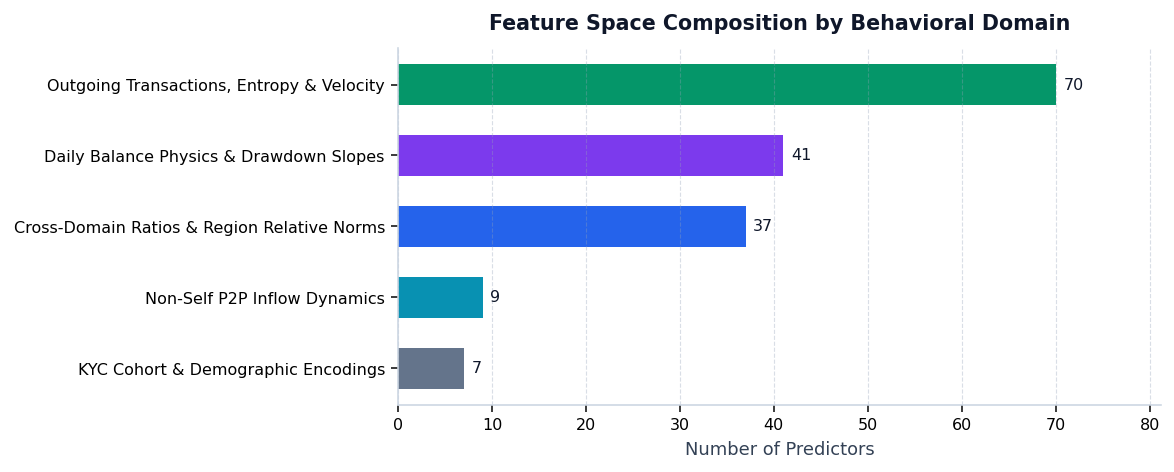

In [6]:
t1 = time.time()

# Sort longitudinal balance records once per account to compute exact day-over-day differences and zero-streak regimes
bal_df = (
    bal_lf
    .filter(pl.col("ACCOUNT_ID").is_in(ACTIVE_IDS))
    .with_columns([
        pl.col("DATE").str.to_date("%Y-%m-%d").alias("_BAL_DATE"),
        pl.col("AVAILABLE_BALANCE").cast(pl.Float32).alias("_BAL"),
    ])
    .filter(pl.col("_BAL_DATE") <= OBS_DATE)
    .select(["ACCOUNT_ID", "_BAL_DATE", "_BAL"])
    .sort(["ACCOUNT_ID", "_BAL_DATE"])
    .collect()
)

# Segment contiguous zero-balance regimes using cumulative regime-change identifiers
bal_df = bal_df.with_columns([
    pl.col("_BAL").diff().over("ACCOUNT_ID").alias("_DBAL"),
    (pl.col("_BAL") == 0.0).alias("_IS_ZERO"),
])
bal_df = bal_df.with_columns([
    (pl.col("_IS_ZERO") != pl.col("_IS_ZERO").shift(1)).fill_null(True).over("ACCOUNT_ID").alias("_ZCHG"),
])
bal_df = bal_df.with_columns([
    pl.col("_ZCHG").cast(pl.Int32).cum_sum().over("ACCOUNT_ID").alias("_ZSTREAK_ID"),
])

zero_streak = (
    bal_df.filter(pl.col("_IS_ZERO"))
    .group_by(["ACCOUNT_ID", "_ZSTREAK_ID"]).agg(pl.len().alias("_slen"))
    .group_by("ACCOUNT_ID").agg(pl.col("_slen").max().cast(pl.Int16).alias("bal_zero_streak_max"))
)

bal_feats = (
    bal_df.group_by("ACCOUNT_ID").agg([
        pl.len().cast(pl.Int16).alias("n_balance_records"),
        pl.col("_BAL").mean().alias("bal_mean"),
        pl.col("_BAL").std().alias("bal_std"),
        pl.col("_BAL").min().alias("bal_min"),
        pl.col("_BAL").quantile(0.10).alias("bal_p10"),
        pl.col("_BAL").median().alias("bal_median"),
        pl.col("_BAL").quantile(0.90).alias("bal_p90"),
        pl.col("_BAL").max().alias("bal_max"),
        pl.col("_BAL").first().alias("bal_first"),
        pl.col("_BAL").last().alias("bal_last"),

        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_7)).mean().alias("bal_mean_7d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_14)).mean().alias("bal_mean_14d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).mean().alias("bal_mean_30d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).std().alias("bal_std_30d"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(D_30)).min().alias("bal_min_30d"),
        pl.col("_BAL").filter((pl.col("_BAL_DATE") >= pl.lit(date(2024, 1, 1))) & (pl.col("_BAL_DATE") < pl.lit(date(2024, 2, 1)))).mean().alias("bal_mean_jan"),
        pl.col("_BAL").filter((pl.col("_BAL_DATE") >= pl.lit(date(2024, 2, 1))) & (pl.col("_BAL_DATE") < pl.lit(date(2024, 3, 1)))).mean().alias("bal_mean_feb"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(date(2024, 3, 1))).mean().alias("bal_mean_mar"),
        pl.col("_BAL").filter(pl.col("_BAL_DATE") >= pl.lit(date(2024, 3, 1))).std().alias("bal_std_mar"),

        pl.col("_IS_ZERO").sum().cast(pl.Int16).alias("zero_bal_days"),
        pl.col("_IS_ZERO").mean().alias("zero_bal_ratio"),
        (pl.col("_BAL") < 10.0).sum().cast(pl.Int16).alias("bal_lt10_days"),
        (pl.col("_DBAL").abs() < 1e-4).sum().cast(pl.Int16).alias("bal_flat_days"),
        (pl.col("_DBAL").abs() < 1.0).sum().cast(pl.Int16).alias("bal_near_flat_days"),
        (pl.col("_DBAL") < -50.0).sum().cast(pl.Int16).alias("bal_neg_jump_days"),
        (pl.col("_DBAL") > 50.0).sum().cast(pl.Int16).alias("bal_pos_jump_days"),
        ((pl.col("_DBAL") < -50.0) & (pl.col("_BAL_DATE") >= pl.lit(D_30))).sum().cast(pl.Int16).alias("bal_neg_jump_30d"),
        ((pl.col("_DBAL") > 50.0) & (pl.col("_BAL_DATE") >= pl.lit(D_30))).sum().cast(pl.Int16).alias("bal_pos_jump_30d"),
        pl.col("_DBAL").min().alias("bal_max_single_drop"),
        pl.col("_DBAL").max().alias("bal_max_single_spike"),
        pl.col("_BAL_DATE").filter(pl.col("_DBAL").abs() >= 1.0).max().alias("_last_bal_move_dt"),
    ])
    .with_columns([
        (pl.lit(OBS_DATE) - pl.col("_last_bal_move_dt")).dt.total_days().cast(pl.Int16).alias("days_since_last_bal_move"),
        ((pl.col("bal_last") - pl.col("bal_first")) / (pl.col("bal_first").abs() + 1.0)).alias("bal_trend"),
        (pl.col("bal_std") / (pl.col("bal_mean").abs() + 1.0)).alias("bal_cv"),
        (pl.col("bal_last") / (pl.col("bal_max") + 1.0)).alias("bal_drain_ratio"),
        (pl.col("bal_max") - pl.col("bal_last")).alias("bal_drawdown_abs"),
        (pl.col("bal_mean_14d") / (pl.col("bal_mean_jan") + 1.0)).alias("bal_14d_vs_jan_ratio"),
        (pl.col("bal_mean_mar") / (pl.col("bal_mean_jan") + 1.0)).alias("bal_mar_vs_jan_ratio"),
    ])
    .drop("_last_bal_move_dt")
)

# Compute full-horizon and half-period weekly OLS balance slopes to detect liquidity acceleration
bal_weekly_raw = (
    bal_df
    .with_columns(((pl.col("_BAL_DATE") - pl.lit(date(2024, 1, 1))).dt.total_days() // 7).alias("week_idx"))
    .group_by(["ACCOUNT_ID", "week_idx"]).agg(pl.col("_BAL").mean().alias("wbal"))
)
bal_slope = (
    bal_weekly_raw.group_by("ACCOUNT_ID").agg([
        pl.len().alias("n_w"), pl.col("week_idx").sum().alias("sx"), pl.col("wbal").sum().alias("sy"),
        (pl.col("week_idx") * pl.col("wbal")).sum().alias("sxy"), (pl.col("week_idx") ** 2).sum().alias("sx2"),
    ]).with_columns([
        ((pl.col("n_w") * pl.col("sxy") - pl.col("sx") * pl.col("sy")) /
         (pl.col("n_w") * pl.col("sx2") - pl.col("sx") ** 2 + 1e-9)).alias("balance_weekly_slope")
    ]).select(["ACCOUNT_ID", "balance_weekly_slope"])
)

_mid = int(bal_weekly_raw["week_idx"].max() // 2) if bal_weekly_raw.height > 0 else 6
def _half_slope(df, lo, hi, suffix):
    sub = df.filter((pl.col("week_idx") >= lo) & (pl.col("week_idx") < hi))
    return (
        sub.group_by("ACCOUNT_ID").agg([
            pl.len().alias(f"n_{suffix}"), pl.col("week_idx").sum().alias(f"sx_{suffix}"),
            pl.col("wbal").sum().alias(f"sy_{suffix}"), (pl.col("week_idx") * pl.col("wbal")).sum().alias(f"sxy_{suffix}"),
            (pl.col("week_idx") ** 2).sum().alias(f"sx2_{suffix}"),
        ]).with_columns([
            ((pl.col(f"n_{suffix}") * pl.col(f"sxy_{suffix}") - pl.col(f"sx_{suffix}") * pl.col(f"sy_{suffix}")) /
             (pl.col(f"n_{suffix}") * pl.col(f"sx2_{suffix}") - pl.col(f"sx_{suffix}") ** 2 + 1e-9)).alias(f"slope_{suffix}")
        ]).select(["ACCOUNT_ID", f"slope_{suffix}"])
    )
slope_h1 = _half_slope(bal_weekly_raw, 0, _mid, "h1")
slope_h2 = _half_slope(bal_weekly_raw, _mid, 100, "h2")

del bal_df, bal_weekly_raw; gc.collect()

def encode_cat_col(df: pl.DataFrame, src_col: str, dst_col: str, dtype) -> pl.DataFrame:
    """Deterministically encode sorted categorical levels with -1 reserved for unseen nulls."""
    vals = sorted([x for x in df[src_col].unique().to_list() if x is not None])
    lkp = pl.DataFrame({src_col: vals, dst_col: list(range(len(vals)))}).with_columns(pl.col(dst_col).cast(dtype))
    return df.join(lkp, on=src_col, how="left").with_columns(pl.col(dst_col).fill_null(-1).cast(dtype))

kyc_feats = kyc.with_columns([
    (pl.lit(OBS_DATE) - pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date)).dt.total_days().cast(pl.Int32).alias("account_tenure_days"),
    pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date).dt.year().cast(pl.Int16).alias("open_year"),
    pl.col("ACCOUNT_OPEN_DATE").cast(pl.Date).dt.month().cast(pl.Int8).alias("open_month"),
    (pl.col("REGION").fill_null("UNK") + "_" + pl.col("GENDER").fill_null("UNK")).alias("_REG_GEN"),
])
kyc_feats = encode_cat_col(kyc_feats, "GENDER", "gender_enc", pl.Int8)
kyc_feats = encode_cat_col(kyc_feats, "REGION", "region_enc", pl.Int16)
kyc_feats = encode_cat_col(kyc_feats, "ACCOUNT_TYPE", "account_type_enc", pl.Int8)
kyc_feats = encode_cat_col(kyc_feats, "_REG_GEN", "region_gender_enc", pl.Int16)
kyc_final = kyc_feats.select([
    "ACCOUNT_ID", "account_tenure_days", "open_year", "open_month",
    "gender_enc", "region_enc", "account_type_enc", "region_gender_enc"
])

def safe_join(base_df: pl.DataFrame, feat_df: pl.DataFrame, on="ACCOUNT_ID", how="left") -> pl.DataFrame:
    """Left-join feature block while dropping pre-existing overlapping columns cleanly."""
    on_cols = [on] if isinstance(on, str) else list(on)
    overlap = [c for c in feat_df.columns if c in base_df.columns and c not in on_cols]
    if overlap:
        base_df = base_df.drop(overlap)
    return base_df.join(feat_df, on=on, how=how)

n_src_cols = (src_agg.shape[1] - 1) + (txn_type_pivot.shape[1] - 1) + (entropy_feat.shape[1] - 1) + 2 + (gap_feats.shape[1] - 1)
n_dst_cols = dst_agg.shape[1] - 1
n_bal_cols = (bal_feats.shape[1] - 1) + 4
n_kyc_cols = kyc_final.shape[1] - 1

master = pl.DataFrame({"ACCOUNT_ID": all_ids_needed})
for f in (src_agg, txn_type_pivot, entropy_feat, txn_count_slope, txn_amt_slope,
          gap_feats, dst_agg, bal_feats, zero_streak, bal_slope, slope_h1, slope_h2, kyc_final):
    master = safe_join(master, f, on="ACCOUNT_ID")

del src_agg, txn_type_pivot, entropy_feat, txn_count_slope, txn_amt_slope, gap_feats, dst_agg, bal_feats, zero_streak, bal_slope, slope_h1, slope_h2, kyc_final
gc.collect()

# Right-cap missing recency and inter-event gap indicators at 91 days to encode full-window inactivity
for c in ["recency_days", "recency_CashIn_days", "recency_CashOut_days", "recency_BillPay_days",
          "recency_MerchantPay_days", "recency_P2P_days", "p2p_in_recency_days",
          "days_since_last_bal_move", "gap_mean", "gap_median", "gap_max", "gap_std", "gap_last"]:
    if c in master.columns:
        master = master.with_columns(pl.col(c).fill_null(91))

nc = master.null_count()
master = master.with_columns([pl.col(c).fill_null(0) for c in master.columns if nc[c][0] > 0])

# Behavioral Interaction & Ratio Features
has_ci  = "type_count_CashIn" in master.columns
has_co  = "type_count_CashOut" in master.columns
has_bp  = "type_count_BillPay" in master.columns
has_mp  = "type_count_MerchantPay" in master.columns

extra_exprs = [
    pl.min_horizontal(["recency_days", "p2p_in_recency_days"]).alias("combined_recency_days"),
    (pl.col("total_inflow") / (pl.col("txn_amount_sum_all") + 1.0)).alias("inflow_outflow_ratio"),
    (pl.col("total_inflow") - pl.col("txn_amount_sum_all")).alias("net_flow"),
    (pl.col("total_inflow_30d") / (pl.col("txn_sum_30d") + 1.0)).alias("inflow_outflow_ratio_30d"),
    (pl.col("p2p_in_cnt") - (pl.col("type_count_P2P") if "type_count_P2P" in master.columns else pl.lit(0))).alias("p2p_net_cnt"),
    (pl.col("p2p_in_sum") - (pl.col("type_sum_P2P") if "type_sum_P2P" in master.columns else pl.lit(0))).alias("p2p_net_amt"),
    (pl.col("n_unique_p2p_receivers") + pl.col("n_unique_p2p_senders")).alias("total_unique_p2p_peers"),
    (pl.col("txn_count_all") / (pl.col("n_unique_counterparties") + 1.0)).alias("counterparty_concentration"),
    (pl.col("txn_amount_p75_all") - pl.col("txn_amount_p25_all")).alias("txn_amount_iqr_all"),
    ((pl.col("txn_amount_mean_all") - pl.col("txn_amount_median_all")) / (pl.col("txn_amount_std_all") + 1.0)).alias("txn_amount_skew_proxy"),
    (pl.col("txn_count_30d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last30d"),
    (pl.col("txn_count_14d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last14d"),
    (pl.col("txn_count_7d") / (pl.col("txn_count_all") + 1.0)).alias("txn_pct_last7d"),
    (pl.col("txn_count_7d") / (pl.col("txn_count_30d") + 1.0)).alias("activity_drop_7v30"),
    (pl.col("txn_count_14d") / (pl.col("txn_count_prev14d") + 1.0)).alias("decay_14d_vs_prev14d"),
    (pl.col("txn_count_30d") / (pl.col("cnt_30_60") + 1.0)).alias("decay_30d_vs_mid30d"),
    (pl.col("txn_count_30d") / (pl.col("cnt_60_90") + 1.0)).alias("decline_recent_vs_old"),
    (pl.col("cnt_30_60") / (pl.col("cnt_60_90") + 1.0)).alias("decline_mid_vs_old"),
    (pl.col("txn_count_30d") - pl.col("cnt_60_90")).alias("decline_abs"),
    (pl.col("cnt_mar") / (pl.col("cnt_jan") + 1.0)).alias("mar_over_jan"),
    (pl.col("cnt_mar") / (pl.col("cnt_feb") + 1.0)).alias("mar_over_feb"),
    (pl.col("recency_days") / (pl.col("gap_mean") + 1.0)).alias("overdue_ratio"),
    ((pl.col("recency_days") - pl.col("gap_median")) / (pl.col("gap_std") + 1.0)).alias("gap_zscore"),
    (pl.col("slope_h2") - pl.col("slope_h1")).alias("balance_acceleration"),
    (pl.col("bal_mean") / (pl.col("txn_amount_mean_all").abs() + 1.0)).alias("balance_to_txn_ratio"),
    (pl.col("recency_days") / (pl.col("account_tenure_days") + 1.0)).alias("recency_to_tenure_ratio"),
    (pl.col("txn_amount_sum_all") / (pl.col("active_days_all") + 1.0)).alias("txn_amt_per_active_day"),
    (pl.col("txn_count_all") / (pl.col("active_days_all") + 1.0)).alias("txn_per_active_day"),
    (pl.col("bal_mean") - pl.col("bal_mean").median().over("region_enc")).alias("bal_diff_region_med"),
    (pl.col("txn_count_all") - pl.col("txn_count_all").median().over("region_enc")).alias("txn_diff_region_med"),
    (pl.col("n_unique_billers") / (pl.col("active_days_all") + 1.0)).alias("billers_per_active_day"),
    (pl.col("n_unique_merchants") / (pl.col("active_days_all") + 1.0)).alias("merchants_per_active_day"),
    (pl.col("txn_amount_p25_all") / (pl.col("txn_amount_median_all") + 1.0)).alias("amt_p25_to_median_ratio"),
    (pl.col("bal_p10") / (pl.col("bal_p90") + 1.0)).alias("bal_p10_to_p90_ratio"),
    (pl.col("cnt_mar") / ((pl.col("cnt_jan") + pl.col("cnt_feb")) * 0.5 + 1.0)).alias("txn_cnt_mar_vs_jan_feb_avg"),
]
if has_ci and has_co:
    extra_exprs.append((pl.col("type_count_CashIn") / (pl.col("type_count_CashOut") + 1.0)).alias("cashin_to_cashout_ratio"))
if has_bp and has_mp:
    extra_exprs.append(((pl.col("type_count_BillPay") + pl.col("type_count_MerchantPay")) / (pl.col("txn_count_all") + 1.0)).alias("utility_merchant_share"))

master = master.with_columns(extra_exprs)
n_ratio_cols = len(extra_exprs)

feature_inventory_df = pd.DataFrame([
    {"Behavioral Domain": "Outgoing Transactions, Entropy & Velocity", "Feature Count": n_src_cols},
    {"Behavioral Domain": "Non-Self P2P Inflow Dynamics", "Feature Count": n_dst_cols},
    {"Behavioral Domain": "Daily Balance Physics & Drawdown Slopes", "Feature Count": n_bal_cols},
    {"Behavioral Domain": "KYC Cohort & Demographic Encodings", "Feature Count": n_kyc_cols},
    {"Behavioral Domain": "Cross-Domain Ratios & Region Relative Norms", "Feature Count": n_ratio_cols},
    {"Behavioral Domain": "Total Assembled Feature Columns (excl. ID)", "Feature Count": master.shape[1] - 1},
])
display_table(feature_inventory_df, title=f"Master Feature Matrix Assembly ({master.shape[0]:,} accounts x {master.shape[1] - 1} predictors in {time.time() - t1:.1f}s)")

fig, ax = plt.subplots(figsize=(8.8, 3.6))
plot_inv = feature_inventory_df.iloc[:-1].sort_values("Feature Count")
bars = ax.barh(plot_inv["Behavioral Domain"], plot_inv["Feature Count"], color=["#64748b", "#0891b2", "#2563eb", "#7c3aed", "#059669"], height=0.58)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.8, b.get_y() + b.get_height() / 2.0, f"{int(w)}", va="center", fontsize=8.5, color="#0f172a")
_style_ax(ax, "Feature Space Composition by Behavioral Domain", "Number of Predictors", grid_axis="x")
ax.set_xlim(0, plot_inv["Feature Count"].max() * 1.16)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_domain_composition.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Behavioral Risk Validation: Activity, Zero-Balance Exposure, and Liquidity Decay

To verify domain validity prior to kernel manifold extraction and modeling, we partition accounts into interpretable tiers based on cumulative transaction count, zero-balance day exposure, and activity recency. Comparing empirical event rates and 30/60/90-day Kaplan-Meier survival estimates confirms monotonic risk separation across behavioral regimes.

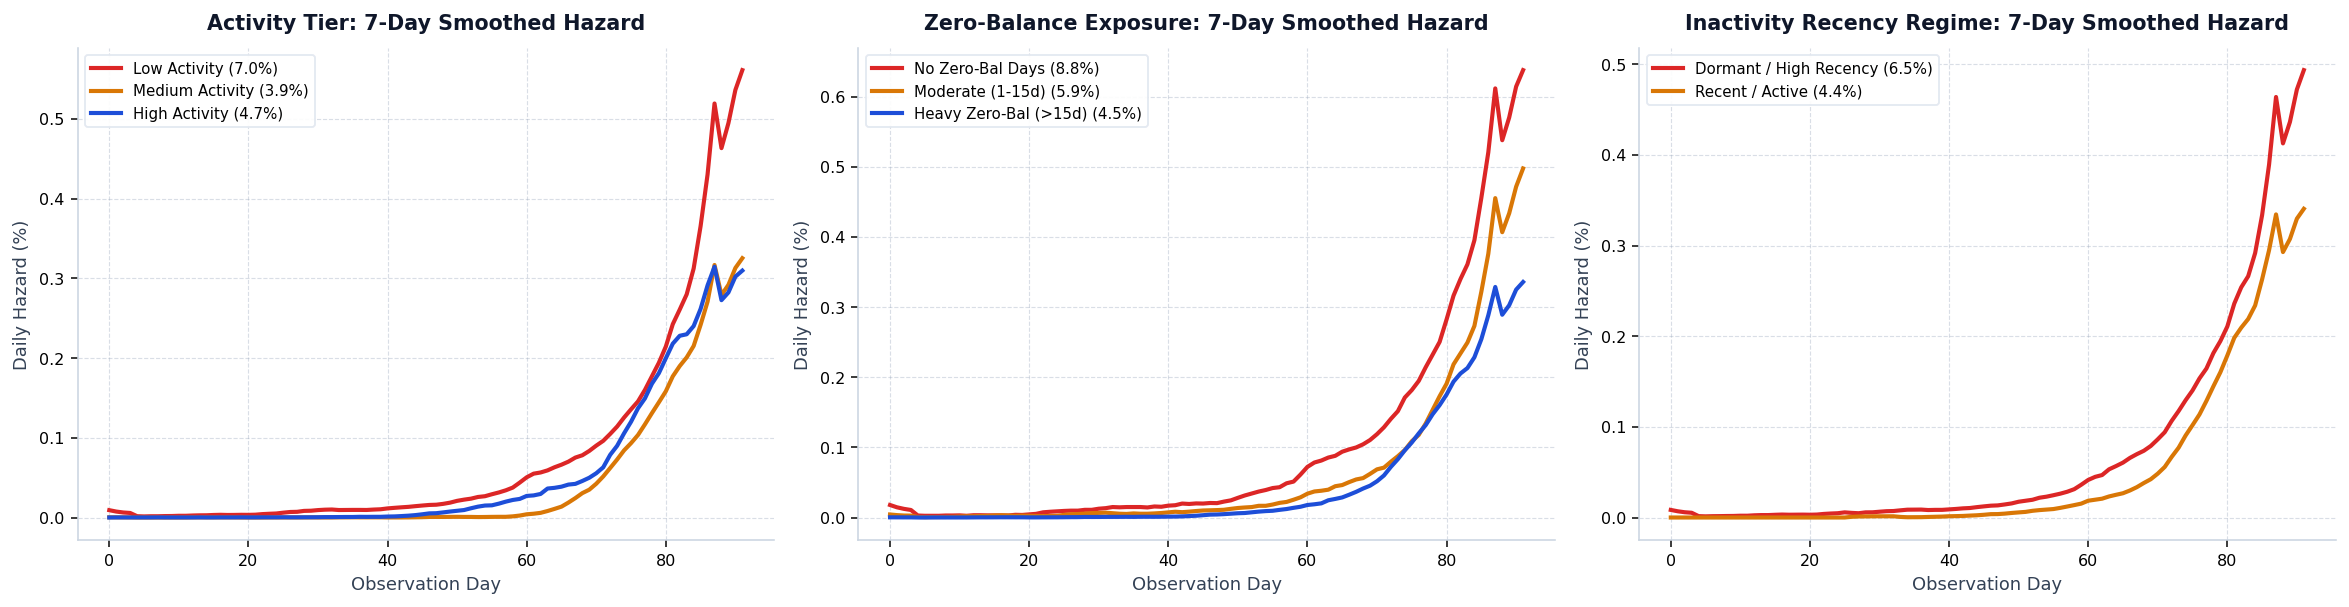

Behavioral Dimension,Tier,Accounts,Churn Events,Churn Rate (%),Hazard / 1k Person-Days,KM 90d Survival (%)
Activity Tier,Low Activity,198333,13902,7.009,0.778,92.991
Activity Tier,Medium Activity,198333,7778,3.922,0.432,96.078
Activity Tier,High Activity,198334,9314,4.696,0.519,95.304
Zero-Balance Exposure,No Zero-Bal Days,72500,6382,8.803,0.981,91.197
Zero-Balance Exposure,Moderate (1-15d),96464,5650,5.857,0.648,94.143
Zero-Balance Exposure,Heavy Zero-Bal (>15d),426036,18962,4.451,0.491,95.549
Inactivity Recency Regime,Dormant / High Recency,224064,14530,6.485,0.719,93.515
Inactivity Recency Regime,Recent / Active,370936,16464,4.439,0.490,95.561


In [7]:
master_tf = master.to_pandas()
del master; gc.collect()

trn_ids = SAMPLE_TRAIN_IDS if USE_SAMPLE else set(all_train_ids)
train = train_labels[train_labels["ACCOUNT_ID"].isin(trn_ids)].merge(master_tf, on="ACCOUNT_ID", how="left")
test  = test_df[["ACCOUNT_ID"]].merge(master_tf, on="ACCOUNT_ID", how="left")
del master_tf; gc.collect()

train["_act_tier"] = pd.qcut(train["txn_count_all"].rank(method="first"), q=3, labels=["Low Activity", "Medium Activity", "High Activity"])
train["_zero_tier"] = pd.cut(train["zero_bal_days"], bins=[-1, 0, 15, 100], labels=["No Zero-Bal Days", "Moderate (1-15d)", "Heavy Zero-Bal (>15d)"])
train["_rec_tier"] = np.where(train["recency_days"] > train["recency_days"].median(), "Dormant / High Recency", "Recent / Active")

behav_rows = []
tier_palette = ["#dc2626", "#d97706", "#1d4ed8"]
fig, axes = plt.subplots(1, 3, figsize=(17.5, 4.6))
for col_seg, title_seg, ax in [
    ("_act_tier", "Activity Tier", axes[0]),
    ("_zero_tier", "Zero-Balance Exposure", axes[1]),
    ("_rec_tier", "Inactivity Recency Regime", axes[2]),
]:
    for idx_v, (val, sub) in enumerate(train.groupby(col_seg, observed=True)):
        kt = kaplan_meier_table(sub["DURATION_DAYS"].values, sub["EVENT_FLAG"].values, max_day=max_day)
        col = tier_palette[idx_v % len(tier_palette)]
        ax.plot(kt["day"], kt["hazard_7d_smooth_pct"], lw=2.2, color=col, label=f"{val} ({sub['EVENT_FLAG'].mean() * 100:.1f}%)")
        behav_rows.append({
            "Behavioral Dimension": title_seg,
            "Tier": str(val),
            "Accounts": len(sub),
            "Churn Events": int(sub["EVENT_FLAG"].sum()),
            "Churn Rate (%)": float(sub["EVENT_FLAG"].mean() * 100.0),
            "Hazard / 1k Person-Days": 1000.0 * float(sub["EVENT_FLAG"].sum()) / max(1.0, float(sub["DURATION_DAYS"].sum())),
            "KM 90d Survival (%)": float(kt.loc[kt["day"] == min(90, max_day), "survival"].values[0] * 100.0),
        })
    _style_ax(ax, f"{title_seg}: 7-Day Smoothed Hazard", "Observation Day", "Daily Hazard (%)")
    ax.legend(loc="upper left", fontsize=8.0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "behavioral_segment_hazards.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

behav_summary = pd.DataFrame(behav_rows)
behav_summary.to_csv(OUTPUT_DIR / "behavioral_segment_hazard_summary.csv", index=False)
display_table(behav_summary, title="Behavioral Tier Churn Incidence and 90-Day Survival Validation", precision=3)

## 8. Subspace RBF Kernel PCA, 5-Fold Cross-Validation Ensemble, and Diagnostic Evaluation

To avoid distance concentration and split dilution in high-dimensional tabular trees, non-linear manifold extraction is restricted within each CV fold (`tr_i`) to a curated `24`-feature core behavioral subspace (`kpca_sub_cols`) alongside out-of-fold smoothed target encodings (`region_enc`, `region_gender_enc`, `open_year`):

1. **Fold-Isolated Landmark RBF Kernel PCA:** Within each training fold, the core subspace is transformed via `_signed_log1p`, standardized and clipped to `[-6, 6]`, and projected onto `8` RBF kernel components (`gamma = 1 / P_sub`) estimated from `1,500` jointly stratified landmarks (`N_KPCA_LANDMARKS = 1500`). Cross-fold basis consistency is enforced via unlabeled $8 \times 8$ Procrustes SVD rotation.
2. **Augmented Level-1 Learners and Bagging Diversity:** The augmented space (`[X, kpca_rbf_00..07]`) trains multi-horizon `LightGBM` ($\{30, 60, 75, 83, 90\}$), `CatBoost` ($\{60, 90\}$), binary/AFT/Cox `XGBoost` (with calibrated `feature_fraction`/`colsample_bytree` to prevent kernel dilution), and regularized bagging `RandomForestClassifier` for low-variance structural diversity.
3. **Level-2 Meta-Stacking, Calibration, and Visual Diagnostics:** Procrustes-aligned manifold projections, logit hazard predictions, log survival outputs, and inter-model dispersion form the meta-matrix (`Z_oof`) for `L2_LGB_Meta`, `L2_XGB_Cox_Meta`, and `L2_RF_Meta`. Final weights are selected via multi-start Powell optimization under full-OOF C-index safeguards, calibrated across horizons ($S(30) \ge S(60) \ge S(90)$), summarized in styled evaluation tables (`kpca_rbf_ensemble_metrics.csv`), and visualized across C-index rankings, discrimination-calibration Pareto frontiers, out-of-fold risk quantile Kaplan-Meier curves, and RBF-KPCA gain profiles.

Training 5-Fold Subspace RBF-KPCA Ensemble | Base=170D, Subspace=24D, KPCA=8D -> Total=178D
Fold 1/5 complete in 1233.1s
Fold 2/5 complete in 1201.9s
Fold 3/5 complete in 1186.2s
Fold 4/5 complete in 1211.7s
Fold 5/5 complete in 1213.0s


Fold,Train Size,Valid Size,KPCA Landmarks,Elapsed (s)
1,"476,000","119,000",1500,1233.1
2,"476,000","119,000",1500,1201.9
3,"476,000","119,000",1500,1186.2
4,"476,000","119,000",1500,1211.7
5,"476,000","119,000",1500,1213.0


Component,Blend Type,Weight
L1_LinearBlend,Risk Meta-Ensemble (powell_l2),0.5925
L2_LGB_Meta,Risk Meta-Ensemble (powell_l2),0.0000
L2_XGB_Cox_Meta,Risk Meta-Ensemble (powell_l2),0.4075
L2_RF_Meta,Risk Meta-Ensemble (powell_l2),0.0000
LGB_90d,90-Day Brier Probability Blend,0.1963
CB_90d,90-Day Brier Probability Blend,0.0918
XGB_90d,90-Day Brier Probability Blend,0.0898
RF_90d,90-Day Brier Probability Blend,0.0000
L2_LGB,90-Day Brier Probability Blend,0.4102
L2_RF,90-Day Brier Probability Blend,0.2119


Horizon,Selected Calibrator,Raw Blend Brier,Calibrated OOF Brier
30d,hybrid,0.00063,0.00048
60d,lr,0.00363,0.00308
90d,raw_l2,0.04632,0.04632


model,oof_c_index,brier_30d,brier_60d,brier_90d,mean_brier,ipcw_brier_30d,ipcw_brier_60d,ipcw_brier_90d,exact_ipcw_ibs
LightGBM 90d (+Subspace RBF-KPCA),0.76745,0.00048,0.00309,0.04634,0.01664,0.00048,0.00309,0.04634,0.01325
LightGBM Multi-Horizon (+RBF-KPCA),0.76404,0.00048,0.00309,0.04634,0.01664,0.00048,0.00309,0.04634,0.01325
CatBoost Classifier (+RBF-KPCA),0.76459,0.00048,0.00308,0.04641,0.01666,0.00048,0.00308,0.04641,0.01326
XGBoost Binary 90d (+RBF-KPCA),0.76712,0.00048,0.00311,0.04636,0.01665,0.00048,0.00311,0.04636,0.01326
XGBoost AFT Survival (+RBF-KPCA),0.76704,0.00048,0.00311,0.04637,0.01665,0.00048,0.00311,0.04637,0.01326
XGBoost Cox PH (+RBF-KPCA),0.76640,0.00048,0.00311,0.04637,0.01665,0.00048,0.00311,0.04637,0.01327
Random Forest 90d (+Subspace RBF-KPCA),0.76611,0.00048,0.00309,0.04639,0.01665,0.00048,0.00309,0.04639,0.01326
L1 Linear Rank Blend,0.76779,0.00048,0.00311,0.04638,0.01666,0.00048,0.00311,0.04638,0.01327
L2 LightGBM Meta-Stacker,0.76784,0.00048,0.00308,0.04634,0.01664,0.00048,0.00308,0.04634,0.01325
L2 XGBoost Cox Meta-Stacker,0.76780,0.00048,0.00311,0.04637,0.01665,0.00048,0.00311,0.04637,0.01327


Evaluation Metric,Value
Final Ensemble 5-Fold OOF C-Index,0.76798
Exact IPCW Integrated Brier Score (IBS),0.01324
Mean Horizon Brier Score (@30 / @60 / @90d),0.01663 (0.00048 / 0.00308 / 0.04632)
Feature Dimensionality (Base + Subspace RBF-KPCA),170 + 8 = 178 (Meta-Matrix 34D)


overall_rank,feature,gain,is_kpca_rbf
1,txn_count_all,131845.60,False
2,kpca_rbf_05,85665.88,True
3,txn_amount_p25_all,62221.92,False
4,txn_count_30d,23289.36,False
5,txn_amount_median_all,18449.42,False
6,txn_count_90d,16833.94,False
7,type_count_CashIn,15820.59,False
8,decline_abs,14336.55,False
9,txn_diff_region_med,13573.20,False
10,kpca_rbf_01,11945.09,True


overall_rank,feature,gain
2,kpca_rbf_05,85665.88
10,kpca_rbf_01,11945.09
12,kpca_rbf_00,10770.12
14,kpca_rbf_04,6673.63
17,kpca_rbf_03,5428.08
34,kpca_rbf_07,3012.88
45,kpca_rbf_06,2248.42
60,kpca_rbf_02,1648.75


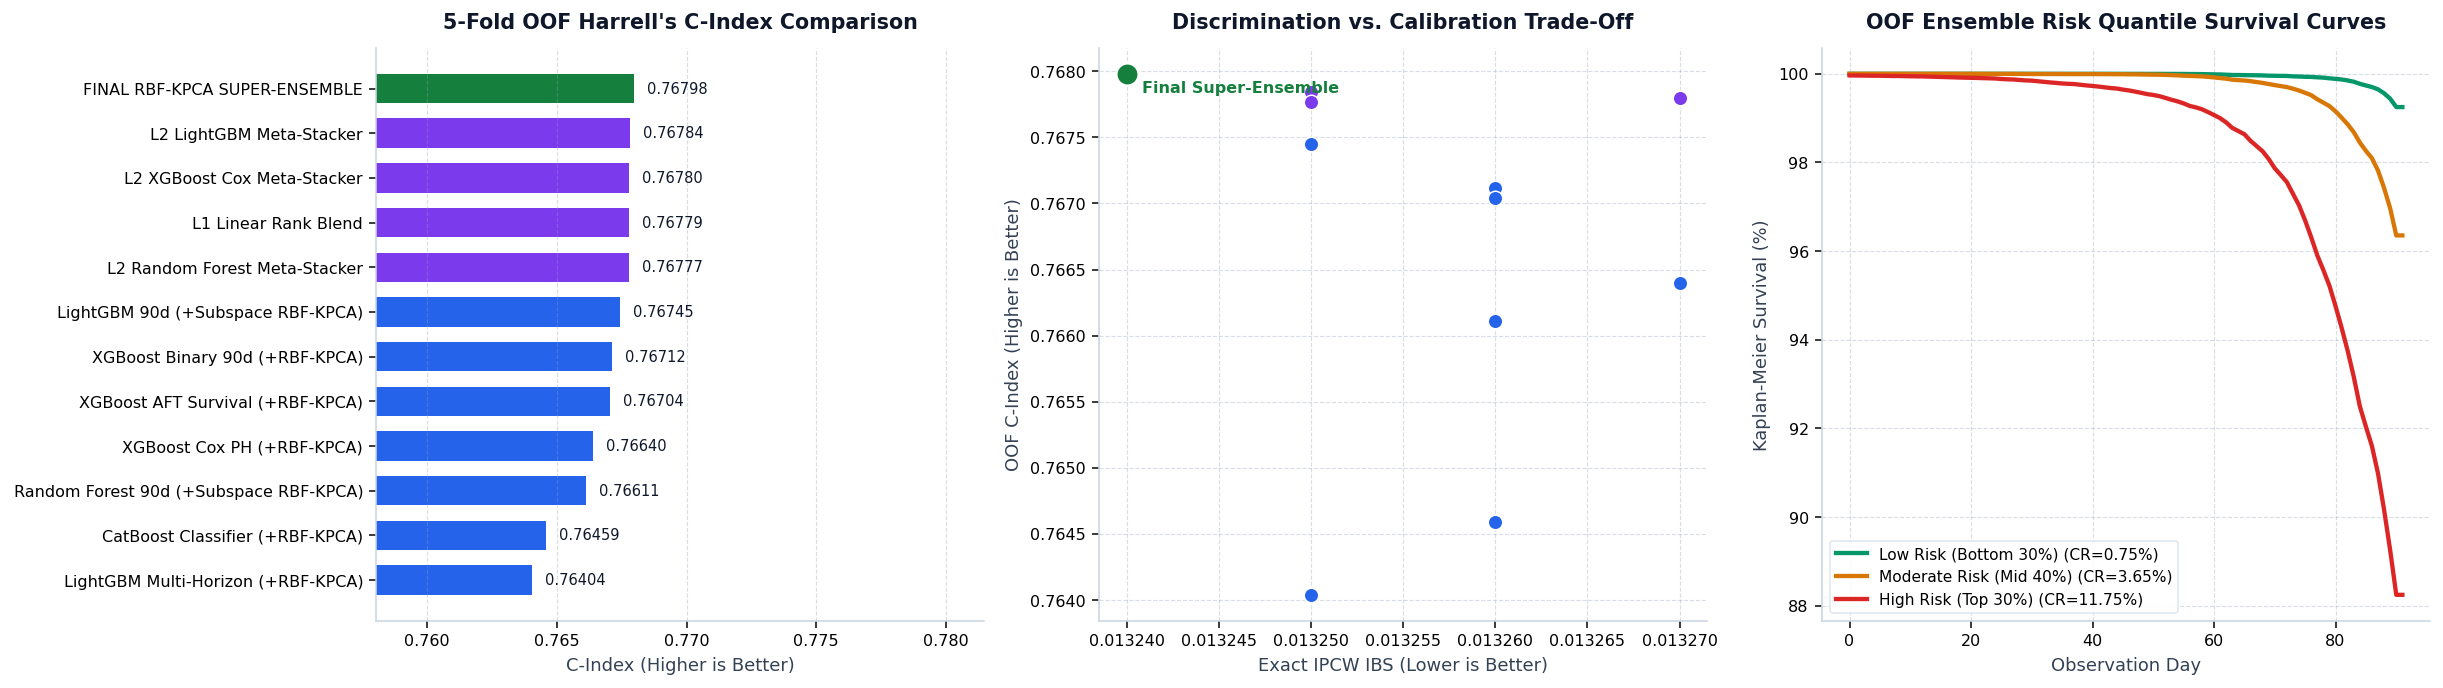

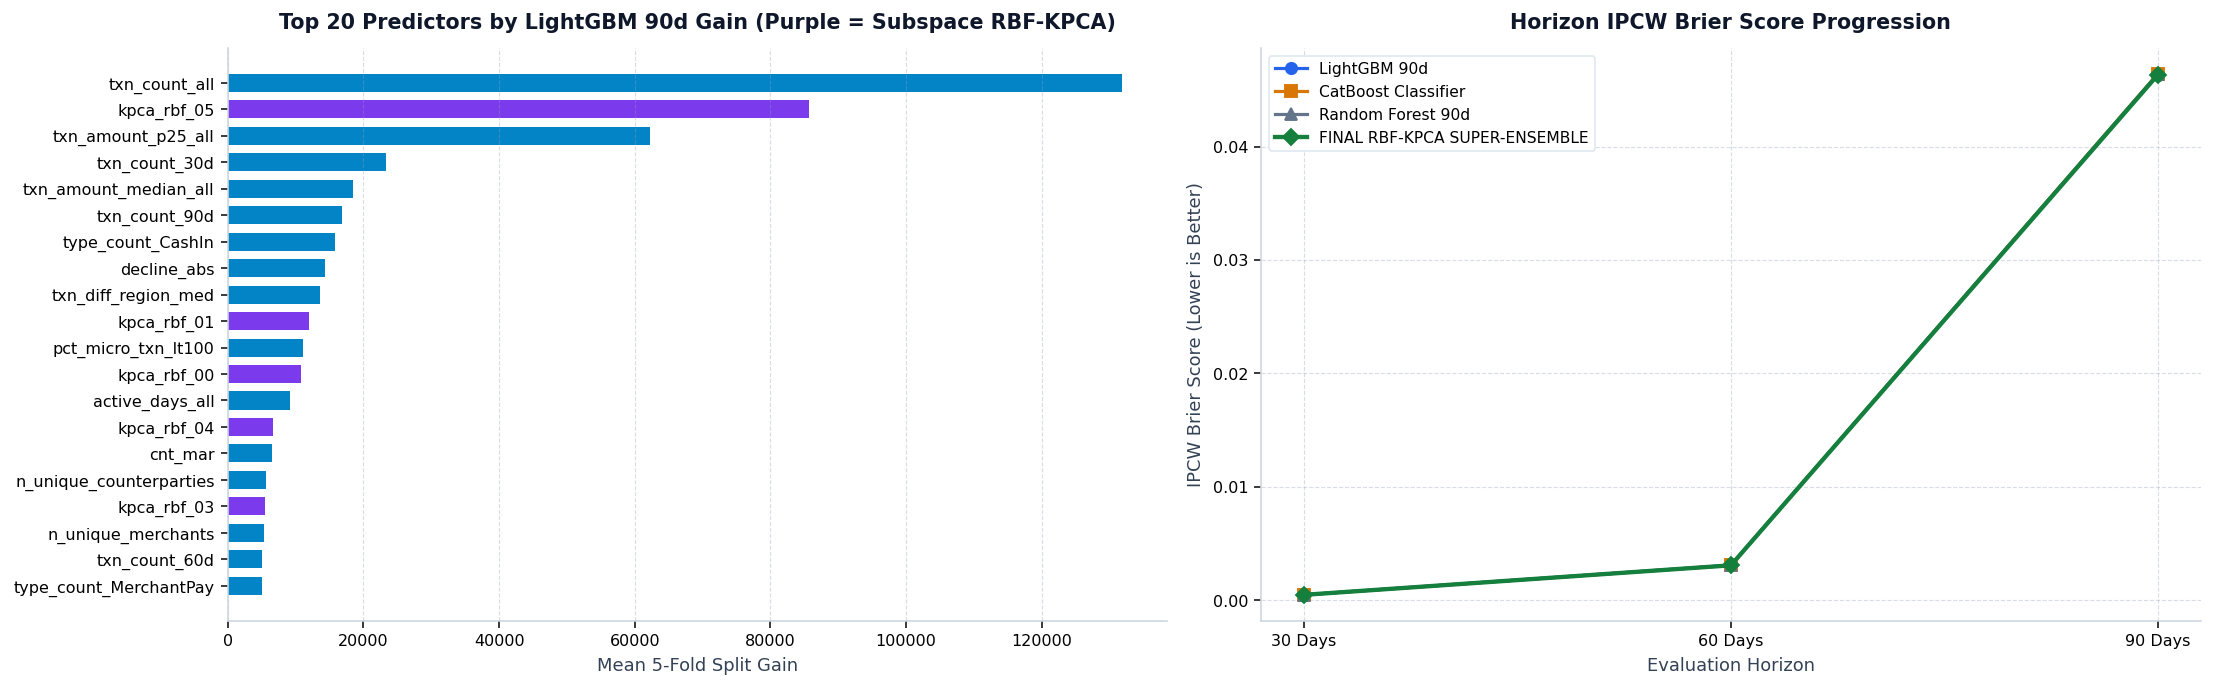

In [8]:
# ==============================================================================
# 8. SUBSPACE RBF KERNEL PCA + 5-FOLD MULTI-PARADIGM ENSEMBLE & DIAGNOSTICS
# ==============================================================================
drop_cols = {"ACCOUNT_ID", "DURATION_DAYS", "EVENT_FLAG", "_act_tier", "_zero_tier", "_rec_tier"}
base_feature_cols = [c for c in train.columns if c not in drop_cols]

event    = train["EVENT_FLAG"].astype(int).values
duration = train["DURATION_DAYS"].astype(float).values
dur_safe = np.maximum(duration, 0.5)  # Enforce strictly positive event times for log-time AFT and Cox partial likelihood

# Jointly stratify folds across event indicator and failure-time intervals
strat_key = np.zeros(len(train), dtype=np.int32)
strat_key[(event == 1) & (duration <= 60)] = 1
strat_key[(event == 1) & (duration > 60) & (duration <= 80)] = 2
strat_key[(event == 1) & (duration > 80)] = 3

N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(train, strat_key))

# Out-of-fold additive-smoothed target encoding on categorical cohorts
te_cols = [c for c in ["region_enc", "region_gender_enc", "open_year"] if c in train.columns]
global_ev = float(event.mean())
global_dur = float(duration.mean())
SMOOTH = 200.0

for col in te_cols:
    oof_ev_te = np.full(len(train), global_ev, dtype=np.float32)
    test_ev_te = np.zeros(len(test), dtype=np.float32)
    oof_du_te = np.full(len(train), global_dur, dtype=np.float32)
    test_du_te = np.zeros(len(test), dtype=np.float32)

    tr_s = train[col].astype(np.int64)
    te_s = test[col].astype(np.int64)
    for tr_i, va_i in folds:
        tmp = pd.DataFrame({"k": tr_s.iloc[tr_i].values, "ev": event[tr_i], "du": duration[tr_i]})
        agg = tmp.groupby("k").agg(cnt=("ev", "count"), ev_sum=("ev", "sum"), du_sum=("du", "sum"))
        ev_map = (agg["ev_sum"] + SMOOTH * global_ev) / (agg["cnt"] + SMOOTH)
        du_map = (agg["du_sum"] + SMOOTH * global_dur) / (agg["cnt"] + SMOOTH)

        oof_ev_te[va_i] = tr_s.iloc[va_i].map(ev_map).fillna(global_ev).values
        oof_du_te[va_i] = tr_s.iloc[va_i].map(du_map).fillna(global_dur).values
        test_ev_te     += te_s.map(ev_map).fillna(global_ev).values / N_FOLDS
        test_du_te     += te_s.map(du_map).fillna(global_dur).values / N_FOLDS

    train[f"{col}_te_ev"] = oof_ev_te
    test[f"{col}_te_ev"]  = test_ev_te
    train[f"{col}_te_du"] = oof_du_te
    test[f"{col}_te_du"]  = test_du_te

feature_cols = [c for c in train.columns if c not in drop_cols]
X     = np.nan_to_num(train[feature_cols].to_numpy(dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)
Xtest = np.nan_to_num(test[feature_cols].to_numpy(dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0)

# Restrict RBF kernel manifold projection to curated 24D core behavioral subspace to prevent high-dimensional distance concentration
kpca_sub_candidates = [
    "txn_count_all", "txn_amount_p25_all", "txn_count_30d", "txn_count_90d",
    "txn_amount_median_all", "pct_micro_txn_lt100", "type_count_CashIn", "cnt_mar",
    "txn_amount_min_all", "txn_diff_region_med", "counterparty_concentration",
    "cashin_to_cashout_ratio", "decline_abs", "active_days_all", "type_count_CashOut",
    "txn_count_60d", "txn_count_14d", "type_count_BillPay", "n_unique_billers",
    "type_count_MerchantPay", "txn_weekly_slope", "gap_std", "recency_days",
    "bal_drain_ratio", "account_tenure_days", "zero_bal_ratio",
]
kpca_sub_cols = [c for c in kpca_sub_candidates if c in feature_cols][:24]
if len(kpca_sub_cols) < 8:
    kpca_sub_cols = feature_cols[:min(24, len(feature_cols))]
kpca_sub_idx = np.array([feature_cols.index(c) for c in kpca_sub_cols], dtype=np.int64)

N_KPCA_COMP      = 8
N_KPCA_LANDMARKS = 1500
KPCA_BATCH_SIZE  = 50000
kpca_cols        = [f"kpca_rbf_{j:02d}" for j in range(N_KPCA_COMP)]
aug_feature_cols = feature_cols + kpca_cols

def _signed_log1p(arr: np.ndarray) -> np.ndarray:
    """Apply sign-preserving log compression to stabilize heavy-tailed monetary predictors."""
    return np.sign(arr) * np.log1p(np.abs(arr))

def _stratified_sample_idx(strata: np.ndarray, n_target: int, rng: np.random.Generator) -> np.ndarray:
    """Draw proportionally stratified landmark indices preserving censoring and timing ratios."""
    if len(strata) <= n_target:
        return np.arange(len(strata))
    uniq, cnts = np.unique(strata, return_counts=True)
    chosen = []
    for u, c in zip(uniq, cnts):
        pool = np.where(strata == u)[0]
        k = max(1, int(round(n_target * c / len(strata))))
        k = min(k, len(pool))
        chosen.append(rng.choice(pool, size=k, replace=False))
    idx_out = np.concatenate(chosen)
    if len(idx_out) > n_target:
        idx_out = rng.choice(idx_out, size=n_target, replace=False)
    return np.sort(idx_out)

def _scale_subspace(scaler_obj, mat_sub: np.ndarray) -> np.ndarray:
    return np.clip(scaler_obj.transform(_signed_log1p(mat_sub.astype(np.float64))), -6.0, 6.0)

def _kpca_transform_batched(kpca_obj, scaler_obj, mat_full: np.ndarray, sub_idx: np.ndarray, batch_size: int = KPCA_BATCH_SIZE) -> np.ndarray:
    """Project arbitrary matrices through fold-fitted landmark RBF KernelPCA in bounded memory batches."""
    n_rows = len(mat_full)
    out = np.zeros((n_rows, kpca_obj.n_components), dtype=np.float32)
    for start in range(0, n_rows, batch_size):
        end = min(n_rows, start + batch_size)
        blk = _scale_subspace(scaler_obj, mat_full[start:end][:, sub_idx])
        out[start:end] = kpca_obj.transform(blk).astype(np.float32)
    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0)

ALL_HORIZONS    = [30, 60, 75, 83, 90]
SUBMIT_HORIZONS = [30, 60, 90]
targets = {t: ((duration <= t) & (event == 1)).astype(np.int8) for t in ALL_HORIZONS}

# Elevated feature_fraction prevents tree column subsampling from diluting compact KPCA components
LGB_BASE = dict(objective="binary", metric="auc", n_jobs=-1, seed=SEED, verbose=-1)
LGB_CONFIGS = {
    30: dict(LGB_BASE, learning_rate=0.02, num_leaves=31, feature_fraction=0.78, bagging_fraction=0.80, bagging_freq=1, min_child_samples=120, scale_pos_weight=15.0, reg_alpha=2.0, reg_lambda=5.0),
    60: dict(LGB_BASE, learning_rate=0.02, num_leaves=47, feature_fraction=0.78, bagging_fraction=0.80, bagging_freq=1, min_child_samples=80,  scale_pos_weight=10.0, reg_alpha=2.0, reg_lambda=5.0),
    75: dict(LGB_BASE, learning_rate=0.02, num_leaves=63, feature_fraction=0.75, bagging_fraction=0.75, bagging_freq=1, min_child_samples=50,  reg_alpha=3.0, reg_lambda=8.0),
    83: dict(LGB_BASE, learning_rate=0.02, num_leaves=95, feature_fraction=0.72, bagging_fraction=0.75, bagging_freq=1, min_child_samples=40,  reg_alpha=4.0, reg_lambda=10.0),
    90: dict(LGB_BASE, learning_rate=0.018, num_leaves=111, feature_fraction=0.72, bagging_fraction=0.75, bagging_freq=1, min_child_samples=35, reg_alpha=5.0, reg_lambda=12.0),
}

lgb_oof       = {t: np.zeros(len(X), dtype=np.float64)     for t in ALL_HORIZONS}
lgb_test      = {t: np.zeros(len(Xtest), dtype=np.float64) for t in ALL_HORIZONS}
cb_oof        = {t: np.zeros(len(X), dtype=np.float64)     for t in [60, 90]}
cb_test       = {t: np.zeros(len(Xtest), dtype=np.float64) for t in [60, 90]}
xgb_bin_oof   = np.zeros(len(X), dtype=np.float64)
xgb_bin_test  = np.zeros(len(Xtest), dtype=np.float64)
xgb_aft_oof   = np.zeros(len(X), dtype=np.float64)
xgb_aft_test  = np.zeros(len(Xtest), dtype=np.float64)
xgb_cox_oof   = np.zeros(len(X), dtype=np.float64)
xgb_cox_test  = np.zeros(len(Xtest), dtype=np.float64)
rf_oof        = np.zeros(len(X), dtype=np.float64)
rf_test       = np.zeros(len(Xtest), dtype=np.float64)

kpca_oof_aligned  = np.zeros((len(X), N_KPCA_COMP), dtype=np.float32)
kpca_test_aligned = np.zeros((len(Xtest), N_KPCA_COMP), dtype=np.float32)
K_te_ref0 = None

gain_imp = np.zeros(len(aug_feature_cols), dtype=np.float64)
xgb_dev = "cuda" if HAS_XGB_CUDA else "cpu"
cb_task = "GPU" if HAS_CB_GPU else "CPU"

print(f"Training 5-Fold Subspace RBF-KPCA Ensemble | Base={X.shape[1]}D, Subspace={len(kpca_sub_idx)}D, KPCA={N_KPCA_COMP}D -> Total={len(aug_feature_cols)}D")

fold_logs = []
for fold, (tr_i, va_i) in enumerate(folds):
    t_f0 = time.time()
    rng_f = np.random.default_rng(SEED + 500 + fold)

    # Fit fold-isolated scaler and randomized landmark RBF KernelPCA strictly on training split tr_i
    sc_idx = _stratified_sample_idx(strat_key[tr_i], min(60000, len(tr_i)), rng_f)
    scaler_f = StandardScaler().fit(_signed_log1p(X[tr_i][sc_idx][:, kpca_sub_idx].astype(np.float64)))

    lm_idx = _stratified_sample_idx(strat_key[tr_i], N_KPCA_LANDMARKS, rng_f)
    X_lm_sc = _scale_subspace(scaler_f, X[tr_i][lm_idx][:, kpca_sub_idx])

    n_comp_f = min(N_KPCA_COMP, max(2, len(X_lm_sc) - 1))
    kpca_f = KernelPCA(
        n_components=n_comp_f,
        kernel="rbf",
        gamma=1.0 / max(1, len(kpca_sub_idx)),
        eigen_solver="randomized",
        random_state=SEED + fold,
        copy_X=False,
    ).fit(X_lm_sc)

    K_tr = _kpca_transform_batched(kpca_f, scaler_f, X[tr_i], kpca_sub_idx)
    K_va = _kpca_transform_batched(kpca_f, scaler_f, X[va_i], kpca_sub_idx)
    K_te = _kpca_transform_batched(kpca_f, scaler_f, Xtest,   kpca_sub_idx)

    if n_comp_f < N_KPCA_COMP:
        K_tr = np.pad(K_tr, ((0, 0), (0, N_KPCA_COMP - n_comp_f)))
        K_va = np.pad(K_va, ((0, 0), (0, N_KPCA_COMP - n_comp_f)))
        K_te = np.pad(K_te, ((0, 0), (0, N_KPCA_COMP - n_comp_f)))

    # Orthogonal Procrustes alignment eliminates arbitrary eigenvector sign/rotation indeterminacy across CV folds
    if fold == 0:
        K_te_ref0 = K_te.copy()
        R_align = np.eye(N_KPCA_COMP, dtype=np.float32)
    else:
        M_cross = (K_te[:min(20000, len(K_te))].T @ K_te_ref0[:min(20000, len(K_te_ref0))]).astype(np.float64)
        U_p, _, Vt_p = np.linalg.svd(M_cross, full_matrices=False)
        R_align = (U_p @ Vt_p).astype(np.float32)
    kpca_oof_aligned[va_i] = K_va @ R_align
    kpca_test_aligned     += (K_te @ R_align) / N_FOLDS

    X_tr_k = np.hstack([X[tr_i], K_tr])
    X_va_k = np.hstack([X[va_i], K_va])
    X_te_k = np.hstack([Xtest,   K_te])

    for t in ALL_HORIZONS:
        y = targets[t]
        dtr = lgb.Dataset(X_tr_k, label=y[tr_i], feature_name=aug_feature_cols)
        dva = lgb.Dataset(X_va_k, label=y[va_i], reference=dtr)
        m = lgb.train(LGB_CONFIGS[t], dtr, num_boost_round=2500, valid_sets=[dva], callbacks=[lgb.early_stopping(120, verbose=False)])
        lgb_oof[t][va_i] = m.predict(X_va_k, num_iteration=m.best_iteration)
        lgb_test[t]     += m.predict(X_te_k, num_iteration=m.best_iteration) / N_FOLDS
        if t == 90:
            gain_imp += m.feature_importance("gain") / N_FOLDS
        del dtr, dva, m

    if HAS_CATBOOST:
        for t in [60, 90]:
            y = targets[t]
            cb = CatBoostClassifier(
                iterations=2200, learning_rate=0.035, depth=7, l2_leaf_reg=10.0,
                eval_metric="Logloss", random_seed=SEED + fold, task_type=cb_task, verbose=False
            )
            cb.fit(X_tr_k, y[tr_i], eval_set=(X_va_k, y[va_i]), early_stopping_rounds=120, verbose=False)
            cb_oof[t][va_i] = cb.predict_proba(X_va_k)[:, 1]
            cb_test[t]     += cb.predict_proba(X_te_k)[:, 1] / N_FOLDS
            del cb

    dtest_xgb_k = xgb.DMatrix(X_te_k)

    dtr_b = xgb.DMatrix(X_tr_k, label=targets[90][tr_i])
    dva_b = xgb.DMatrix(X_va_k, label=targets[90][va_i])
    mb = xgb.train(
        {"objective": "binary:logistic", "eval_metric": "auc", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 6, "learning_rate": 0.025, "subsample": 0.8, "colsample_bytree": 0.72,
         "min_child_weight": 30, "reg_alpha": 4.0, "reg_lambda": 10.0, "seed": SEED + fold},
        dtr_b, num_boost_round=2000, evals=[(dva_b, "val")], early_stopping_rounds=100, verbose_eval=False
    )
    xgb_bin_oof[va_i] = mb.predict(dva_b, iteration_range=(0, mb.best_iteration + 1))
    xgb_bin_test     += mb.predict(dtest_xgb_k, iteration_range=(0, mb.best_iteration + 1)) / N_FOLDS

    dtr_a = xgb.DMatrix(X_tr_k)
    dtr_a.set_float_info("label_lower_bound", dur_safe[tr_i])
    dtr_a.set_float_info("label_upper_bound", np.where(event[tr_i] == 1, dur_safe[tr_i], np.inf))
    dva_a = xgb.DMatrix(X_va_k)
    dva_a.set_float_info("label_lower_bound", dur_safe[va_i])
    dva_a.set_float_info("label_upper_bound", np.where(event[va_i] == 1, dur_safe[va_i], np.inf))
    ma = xgb.train(
        {"objective": "survival:aft", "eval_metric": "aft-nloglik", "aft_loss_distribution": "normal",
         "aft_loss_distribution_scale": 1.1, "tree_method": "hist", "device": xgb_dev,
         "max_depth": 6, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.72,
         "min_child_weight": 30, "reg_lambda": 10.0, "seed": SEED + fold},
        dtr_a, num_boost_round=1500, evals=[(dva_a, "val")], early_stopping_rounds=80, verbose_eval=False
    )
    xgb_aft_oof[va_i] = 1.0 / np.clip(ma.predict(dva_a, iteration_range=(0, ma.best_iteration + 1)), 1e-6, None)
    xgb_aft_test     += (1.0 / np.clip(ma.predict(dtest_xgb_k, iteration_range=(0, ma.best_iteration + 1)), 1e-6, None)) / N_FOLDS

    # Signed duration encodes uncensored events (>0) vs right-censored observations (<0) in XGBoost Cox PH
    y_cox_tr = np.where(event[tr_i] == 1, dur_safe[tr_i], -dur_safe[tr_i])
    y_cox_va = np.where(event[va_i] == 1, dur_safe[va_i], -dur_safe[va_i])
    dtr_c = xgb.DMatrix(X_tr_k, label=y_cox_tr)
    dva_c = xgb.DMatrix(X_va_k, label=y_cox_va)
    mc = xgb.train(
        {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 5, "learning_rate": 0.025, "subsample": 0.8, "colsample_bytree": 0.72,
         "min_child_weight": 30, "reg_alpha": 4.0, "reg_lambda": 12.0, "seed": SEED + fold},
        dtr_c, num_boost_round=1500, evals=[(dva_c, "val")], early_stopping_rounds=80, verbose_eval=False
    )
    xgb_cox_oof[va_i] = mc.predict(dva_c, iteration_range=(0, mc.best_iteration + 1))
    xgb_cox_test     += mc.predict(dtest_xgb_k, iteration_range=(0, mc.best_iteration + 1)) / N_FOLDS

    rf_k = RandomForestClassifier(
        n_estimators=180,
        max_depth=14,
        min_samples_leaf=min(80, max(5, len(tr_i) // 500)),
        max_features=0.35,
        max_samples=0.40,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED + 700 + fold,
    )
    rf_k.fit(X_tr_k, targets[90][tr_i])
    rf_oof[va_i] = rf_k.predict_proba(X_va_k)[:, 1]
    rf_test     += rf_k.predict_proba(X_te_k)[:, 1] / N_FOLDS

    elapsed_f = round(time.time() - t_f0, 1)
    fold_logs.append({"Fold": fold + 1, "Train Size": f"{len(tr_i):,}", "Valid Size": f"{len(va_i):,}", "KPCA Landmarks": n_comp_f if len(X_lm_sc) < N_KPCA_LANDMARKS else N_KPCA_LANDMARKS, "Elapsed (s)": elapsed_f})
    print(f"Fold {fold + 1}/{N_FOLDS} complete in {elapsed_f:.1f}s")

    del dtest_xgb_k, dtr_b, dva_b, mb, dtr_a, dva_a, ma, dtr_c, dva_c, mc, rf_k
    del X_tr_k, X_va_k, X_te_k, K_tr, K_va, K_te
    gc.collect()

if not HAS_CATBOOST:
    for t in [60, 90]:
        cb_oof[t]  = lgb_oof[t].copy()
        cb_test[t] = lgb_test[t].copy()

fold_log_df = pd.DataFrame(fold_logs)
display_table(fold_log_df, title="5-Fold Cross-Validation Execution Summary", precision=1)

lgb_multi_oof  = (0.02 * rankdata(lgb_oof[30]) + 0.05 * rankdata(lgb_oof[60]) + 0.13 * rankdata(lgb_oof[75]) + 0.25 * rankdata(lgb_oof[83]) + 0.55 * rankdata(lgb_oof[90])) / len(X)
lgb_multi_test = (0.02 * rankdata(lgb_test[30]) + 0.05 * rankdata(lgb_test[60]) + 0.13 * rankdata(lgb_test[75]) + 0.25 * rankdata(lgb_test[83]) + 0.55 * rankdata(lgb_test[90])) / len(Xtest)

# ------------------------------------------------------------------------------
# Level-2 Non-Linear Meta-Stacking & Full-OOF Powell Concordance Optimization
# ------------------------------------------------------------------------------
def _safe_logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-6, 1.0 - 1e-6)
    return np.log(p / (1.0 - p))

rank_mat_oof = np.column_stack([
    rankdata(lgb_oof[90]) / len(X),
    lgb_multi_oof,
    rankdata(cb_oof[90]) / len(X),
    rankdata(xgb_bin_oof) / len(X),
    rankdata(xgb_aft_oof) / len(X),
    rankdata(xgb_cox_oof) / len(X),
    rankdata(rf_oof) / len(X),
])
rank_mat_test = np.column_stack([
    rankdata(lgb_test[90]) / len(Xtest),
    lgb_multi_test,
    rankdata(cb_test[90]) / len(Xtest),
    rankdata(xgb_bin_test) / len(Xtest),
    rankdata(xgb_aft_test) / len(Xtest),
    rankdata(xgb_cox_test) / len(Xtest),
    rankdata(rf_test) / len(Xtest),
])

r5_oof  = rank_mat_oof[:, [0, 2, 3, 4, 5]]
r5_test = rank_mat_test[:, [0, 2, 3, 4, 5]]

ctx_candidates = [
    "counterparty_concentration", "txn_count_all", "recency_days",
    "account_tenure_days", "bal_drain_ratio", "gap_std",
    "txn_type_entropy", "active_days_all"
]
ctx_cols = [c for c in ctx_candidates if c in feature_cols]
ctx_idx  = [feature_cols.index(c) for c in ctx_cols]

kpca_norm_oof  = np.linalg.norm(kpca_oof_aligned, axis=1, keepdims=True)
kpca_norm_test = np.linalg.norm(kpca_test_aligned, axis=1, keepdims=True)

Z_oof = np.column_stack([
    _safe_logit(lgb_oof[30]), _safe_logit(lgb_oof[60]), _safe_logit(lgb_oof[75]),
    _safe_logit(lgb_oof[83]), _safe_logit(lgb_oof[90]), lgb_multi_oof,
    _safe_logit(cb_oof[60]),  _safe_logit(cb_oof[90]),  _safe_logit(xgb_bin_oof),
    _safe_logit(rf_oof),
    np.log1p(np.clip(xgb_aft_oof, 0.0, 1e4)),
    np.log1p(np.clip(xgb_cox_oof, 0.0, 1e4)),
    r5_oof.std(axis=1),
    r5_oof.max(axis=1) - r5_oof.min(axis=1),
    rank_mat_oof[:, 4] - rank_mat_oof[:, 0],
    rank_mat_oof[:, 5] - rank_mat_oof[:, 2],
    rank_mat_oof[:, 0] - rank_mat_oof[:, 2],
    lgb_oof[90] - lgb_oof[75],
    lgb_oof[90] - lgb_oof[60],
    kpca_norm_oof,
    kpca_oof_aligned[:, :min(6, N_KPCA_COMP)],
    X[:, ctx_idx],
]).astype(np.float32)

Z_test = np.column_stack([
    _safe_logit(lgb_test[30]), _safe_logit(lgb_test[60]), _safe_logit(lgb_test[75]),
    _safe_logit(lgb_test[83]), _safe_logit(lgb_test[90]), lgb_multi_test,
    _safe_logit(cb_test[60]),  _safe_logit(cb_test[90]),  _safe_logit(xgb_bin_test),
    _safe_logit(rf_test),
    np.log1p(np.clip(xgb_aft_test, 0.0, 1e4)),
    np.log1p(np.clip(xgb_cox_test, 0.0, 1e4)),
    r5_test.std(axis=1),
    r5_test.max(axis=1) - r5_test.min(axis=1),
    rank_mat_test[:, 4] - rank_mat_test[:, 0],
    rank_mat_test[:, 5] - rank_mat_test[:, 2],
    rank_mat_test[:, 0] - rank_mat_test[:, 2],
    lgb_test[90] - lgb_test[75],
    lgb_test[90] - lgb_test[60],
    kpca_norm_test,
    kpca_test_aligned[:, :min(6, N_KPCA_COMP)],
    Xtest[:, ctx_idx],
]).astype(np.float32)

Z_oof  = np.nan_to_num(Z_oof,  nan=0.0, posinf=10.0, neginf=-10.0)
Z_test = np.nan_to_num(Z_test, nan=0.0, posinf=10.0, neginf=-10.0)

l2_lgb_oof  = np.zeros(len(X), dtype=np.float64)
l2_lgb_test = np.zeros(len(Xtest), dtype=np.float64)
l2_cox_oof  = np.zeros(len(X), dtype=np.float64)
l2_cox_test = np.zeros(len(Xtest), dtype=np.float64)
l2_rf_oof   = np.zeros(len(X), dtype=np.float64)
l2_rf_test  = np.zeros(len(Xtest), dtype=np.float64)

dtest_z = xgb.DMatrix(Z_test)
for fold, (tr_i, va_i) in enumerate(folds):
    dtr_m = lgb.Dataset(Z_oof[tr_i], label=targets[90][tr_i])
    dva_m = lgb.Dataset(Z_oof[va_i], label=targets[90][va_i], reference=dtr_m)
    m_l2_lgb = lgb.train(
        {"objective": "binary", "metric": "binary_logloss", "learning_rate": 0.02,
         "max_depth": 3, "num_leaves": 7, "min_child_samples": 200,
         "feature_fraction": 0.75, "bagging_fraction": 0.80, "bagging_freq": 1,
         "reg_alpha": 5.0, "reg_lambda": 25.0, "n_jobs": -1, "seed": SEED + 100 + fold, "verbose": -1},
        dtr_m, num_boost_round=1200, valid_sets=[dva_m], callbacks=[lgb.early_stopping(80, verbose=False)]
    )
    l2_lgb_oof[va_i] = m_l2_lgb.predict(Z_oof[va_i], num_iteration=m_l2_lgb.best_iteration)
    l2_lgb_test     += m_l2_lgb.predict(Z_test,      num_iteration=m_l2_lgb.best_iteration) / N_FOLDS

    y_cox_tr = np.where(event[tr_i] == 1, dur_safe[tr_i], -dur_safe[tr_i])
    y_cox_va = np.where(event[va_i] == 1, dur_safe[va_i], -dur_safe[va_i])
    dtr_mc = xgb.DMatrix(Z_oof[tr_i], label=y_cox_tr)
    dva_mc = xgb.DMatrix(Z_oof[va_i], label=y_cox_va)
    m_l2_cox = xgb.train(
        {"objective": "survival:cox", "eval_metric": "cox-nloglik", "tree_method": "hist", "device": xgb_dev,
         "max_depth": 3, "learning_rate": 0.02, "subsample": 0.80, "colsample_bytree": 0.75,
         "min_child_weight": 80, "reg_alpha": 5.0, "reg_lambda": 30.0, "seed": SEED + 200 + fold},
        dtr_mc, num_boost_round=1000, evals=[(dva_mc, "val")], early_stopping_rounds=60, verbose_eval=False
    )
    l2_cox_oof[va_i] = m_l2_cox.predict(dva_mc, iteration_range=(0, m_l2_cox.best_iteration + 1))
    l2_cox_test     += m_l2_cox.predict(dtest_z, iteration_range=(0, m_l2_cox.best_iteration + 1)) / N_FOLDS

    l2_rf = RandomForestClassifier(
        n_estimators=220,
        max_depth=6,
        min_samples_leaf=min(200, max(5, len(tr_i) // 300)),
        max_features=0.55,
        max_samples=0.70,
        bootstrap=True,
        n_jobs=-1,
        random_state=SEED + 300 + fold,
    )
    l2_rf.fit(Z_oof[tr_i], targets[90][tr_i])
    l2_rf_oof[va_i] = l2_rf.predict_proba(Z_oof[va_i])[:, 1]
    l2_rf_test     += l2_rf.predict_proba(Z_test)[:, 1] / N_FOLDS

# Optimize ensemble blend weights over stratified sub-cohort before full-OOF candidate selection
ev_idx = np.where(event == 1)[0]
ne_idx = np.where(event == 0)[0]
rng_opt = np.random.default_rng(SEED)
sub_opt = np.concatenate([ev_idx, rng_opt.choice(ne_idx, size=min(150000, len(ne_idx)), replace=False)])

def _opt_weights(mat_oof):
    """Maximize Harrell's C-index over the probability simplex using multi-start Powell search."""
    k_cols = mat_oof.shape[1]
    col_scores = np.array([exact_concordance_index_censored(event[sub_opt].astype(bool), duration[sub_opt], mat_oof[sub_opt, j])[0] for j in range(k_cols)])
    best_j = int(np.argmax(col_scores))
    w_best_single = np.zeros(k_cols); w_best_single[best_j] = 1.0
    w_top2 = np.zeros(k_cols); top2_idx = np.argsort(col_scores)[-min(2, k_cols):]; w_top2[top2_idx] = 1.0 / len(top2_idx)
    starts = [np.ones(k_cols) / k_cols, w_top2, w_best_single]

    def _neg_c(raw_w):
        w = np.maximum(raw_w, 0.0)
        if w.sum() <= 1e-12:
            return 0.0
        w /= w.sum()
        return -exact_concordance_index_censored(event[sub_opt].astype(bool), duration[sub_opt], mat_oof[sub_opt] @ w)[0]

    best_w, best_val = w_top2, _neg_c(w_top2)
    for x0 in starts:
        res = minimize(_neg_c, x0=x0, method="Powell", options={"maxiter": 250})
        w = np.maximum(res.x, 0.0)
        if w.sum() > 0:
            w = w / w.sum()
            val = _neg_c(w)
            if val < best_val:
                best_val, best_w = val, w
    return best_w

w_l1 = _opt_weights(rank_mat_oof)
l1_blend_oof  = rank_mat_oof  @ w_l1
l1_blend_test = rank_mat_test @ w_l1

stack_cand_oof = np.column_stack([
    l1_blend_oof,
    rankdata(l2_lgb_oof) / len(X),
    rankdata(l2_cox_oof) / len(X),
    rankdata(l2_rf_oof) / len(X),
])
stack_cand_test = np.column_stack([
    l1_blend_test,
    rankdata(l2_lgb_test) / len(Xtest),
    rankdata(l2_cox_test) / len(Xtest),
    rankdata(l2_rf_test) / len(Xtest),
])
w_l2 = _opt_weights(stack_cand_oof)
stack_names = ["L1_LinearBlend", "L2_LGB_Meta", "L2_XGB_Cox_Meta", "L2_RF_Meta"]

full_cands = {
    "powell_l2": (stack_cand_oof @ w_l2, stack_cand_test @ w_l2, w_l2),
    "lgb_cox_50_50": (
        0.5 * stack_cand_oof[:, 1] + 0.5 * stack_cand_oof[:, 2],
        0.5 * stack_cand_test[:, 1] + 0.5 * stack_cand_test[:, 2],
        np.array([0.0, 0.5, 0.5, 0.0])
    ),
    "lgb_cox_70_30": (
        0.7 * stack_cand_oof[:, 1] + 0.3 * stack_cand_oof[:, 2],
        0.7 * stack_cand_test[:, 1] + 0.3 * stack_cand_test[:, 2],
        np.array([0.0, 0.7, 0.3, 0.0])
    ),
}
for j, nm in enumerate(stack_names):
    w_s = np.zeros(len(stack_names)); w_s[j] = 1.0
    full_cands[f"only_{nm}"] = (stack_cand_oof[:, j], stack_cand_test[:, j], w_s)

best_key = max(full_cands, key=lambda k: float(concordance_index_censored(event.astype(bool), duration, full_cands[k][0])[0]))
risk_oof, risk_test, w_final = full_cands[best_key]

# ------------------------------------------------------------------------------
# Out-of-Fold Probability Calibration and Strict Survival Monotonicity
# ------------------------------------------------------------------------------
p90_mat_oof  = np.column_stack([lgb_oof[90], cb_oof[90], xgb_bin_oof, rf_oof, l2_lgb_oof, l2_rf_oof])
p90_mat_test = np.column_stack([lgb_test[90], cb_test[90], xgb_bin_test, rf_test, l2_lgb_test, l2_rf_test])
def _brier90(raw_w):
    w = np.maximum(raw_w, 0.0)
    if w.sum() <= 1e-12:
        return 1.0
    w /= w.sum()
    return float(np.mean((targets[90] - (p90_mat_oof @ w)) ** 2))
res_b90 = minimize(_brier90, x0=np.ones(p90_mat_oof.shape[1]) / p90_mat_oof.shape[1], method="Powell")
w_b90 = np.maximum(res_b90.x, 0.0)
w_b90 = w_b90 / w_b90.sum() if w_b90.sum() > 0 else np.ones(p90_mat_oof.shape[1]) / p90_mat_oof.shape[1]

raw_p_oof = {
    30: lgb_oof[30],
    60: 0.55 * lgb_oof[60] + 0.45 * cb_oof[60],
    90: p90_mat_oof @ w_b90,
}
raw_p_test = {
    30: lgb_test[30],
    60: 0.55 * lgb_test[60] + 0.45 * cb_test[60],
    90: p90_mat_test @ w_b90,
}

def _calibrate_oof_prob(raw_oof_p, raw_te_p, y_t):
    """Select minimum-Brier horizon calibrator out-of-fold across raw, isotonic, logistic, and hybrid mappings."""
    iso_o = np.zeros(len(X), dtype=np.float64)
    iso_t = np.zeros(len(Xtest), dtype=np.float64)
    lr_o  = np.zeros(len(X), dtype=np.float64)
    lr_t  = np.zeros(len(Xtest), dtype=np.float64)
    has_lr = True
    for tr_i, va_i in folds:
        iso = IsotonicRegression(out_of_bounds="clip").fit(raw_oof_p[tr_i], y_t[tr_i])
        iso_o[va_i] = np.clip(iso.predict(raw_oof_p[va_i]), 1e-6, 1.0 - 1e-6)
        iso_t      += np.clip(iso.predict(raw_te_p),        1e-6, 1.0 - 1e-6) / N_FOLDS
        if int(y_t[tr_i].sum()) >= 5:
            sc = StandardScaler().fit(Z_oof[tr_i, :19])
            lr = LogisticRegression(C=0.25, max_iter=1000).fit(sc.transform(Z_oof[tr_i, :19]), y_t[tr_i])
            lr_o[va_i] = np.clip(lr.predict_proba(sc.transform(Z_oof[va_i, :19]))[:, 1], 1e-6, 1.0 - 1e-6)
            lr_t      += np.clip(lr.predict_proba(sc.transform(Z_test[:, :19]))[:, 1],   1e-6, 1.0 - 1e-6) / N_FOLDS
        else:
            has_lr = False
    if not has_lr:
        return iso_o, iso_t, "iso"
    cands = {
        "raw_l2": (np.clip(raw_oof_p, 1e-6, 1.0 - 1e-6), np.clip(raw_te_p, 1e-6, 1.0 - 1e-6)),
        "iso":    (iso_o, iso_t),
        "lr":     (lr_o, lr_t),
        "hybrid": (0.5 * lr_o + 0.5 * iso_o, 0.5 * lr_t + 0.5 * iso_t),
    }
    best_name = min(cands, key=lambda k: float(np.mean((y_t - cands[k][0]) ** 2)))
    return cands[best_name][0], cands[best_name][1], best_name

oof_c, test_c, cal_rows = {}, {}, []
for t in SUBMIT_HORIZONS:
    oof_c[t], test_c[t], best_cal = _calibrate_oof_prob(raw_p_oof[t], raw_p_test[t], targets[t])
    cal_rows.append({
        "Horizon": f"{t}d",
        "Selected Calibrator": best_cal,
        "Raw Blend Brier": float(np.mean((targets[t] - np.clip(raw_p_oof[t], 1e-6, 1.0 - 1e-6)) ** 2)),
        "Calibrated OOF Brier": float(np.mean((targets[t] - oof_c[t]) ** 2)),
    })

def enforce_monotone(pdict):
    """Project cumulative event probabilities so S(30) >= S(60) >= S(90)."""
    p30, p60, p90 = pdict[30].copy(), pdict[60].copy(), pdict[90].copy()
    p60 = np.maximum(p30, p60)
    p90 = np.maximum(p60, p90)
    return {30: p30, 60: p60, 90: p90}

oof_m, test_m = enforce_monotone(oof_c), enforce_monotone(test_c)
oof_S  = {t: 1.0 - oof_m[t]  for t in SUBMIT_HORIZONS}
test_S = {t: 1.0 - test_m[t] for t in SUBMIT_HORIZONS}

blend_weights_df = pd.DataFrame([
    {"Component": nm, "Blend Type": f"Risk Meta-Ensemble ({best_key})", "Weight": round(float(w), 4)}
    for nm, w in zip(stack_names, w_final)
] + [
    {"Component": nm, "Blend Type": "90-Day Brier Probability Blend", "Weight": round(float(w), 4)}
    for nm, w in zip(["LGB_90d", "CB_90d", "XGB_90d", "RF_90d", "L2_LGB", "L2_RF"], w_b90)
])
display_table(blend_weights_df, title="Optimized Meta-Ensemble and 90-Day Brier Blend Weights", precision=4)
display_table(pd.DataFrame(cal_rows), title="Horizon-Specific Out-of-Fold Probability Calibration Diagnostics", precision=5, min_cols_highlight=["Calibrated OOF Brier"])

# ------------------------------------------------------------------------------
# Exact 5-Fold Cross-Validation Evaluation Tables & Visualizations
# ------------------------------------------------------------------------------
y_str = Surv.from_arrays(event=event.astype(bool), time=duration)

def _quick_iso_curve(p30_raw, p60_raw, p90_raw):
    s_out = {}
    for t, r_raw in [(30, p30_raw), (60, p60_raw), (90, p90_raw)]:
        cal_p = np.zeros(len(X), dtype=np.float64)
        yt = targets[t]
        for tr_i, va_i in folds:
            iso_k = IsotonicRegression(out_of_bounds="clip").fit(r_raw[tr_i], yt[tr_i])
            cal_p[va_i] = np.clip(iso_k.predict(r_raw[va_i]), 1e-6, 1.0 - 1e-6)
        s_out[t] = 1.0 - cal_p
    s_out[60] = np.minimum(s_out[30], s_out[60])
    s_out[90] = np.minimum(s_out[60], s_out[90])
    return s_out

def _eval_row(model_name, risk_vec, s_dict):
    ci = float(concordance_index_censored(event.astype(bool), duration, risk_vec)[0])
    bs_unw = {t: float(np.mean(((duration > t).astype(float) - s_dict[t]) ** 2)) for t in SUBMIT_HORIZONS}
    s_mat = np.column_stack([s_dict[30], s_dict[60], s_dict[90]])
    ipcw_bs, _ = exact_ipcw_brier_at_times(y_str, y_str, s_mat, np.array(SUBMIT_HORIZONS))
    ibs_sk_val = float(integrated_brier_score(y_str, y_str, s_mat, np.array(SUBMIT_HORIZONS)))
    return {
        "model": model_name,
        "oof_c_index": round(ci, 5),
        "brier_30d": round(bs_unw[30], 5),
        "brier_60d": round(bs_unw[60], 5),
        "brier_90d": round(bs_unw[90], 5),
        "mean_brier": round(float(np.mean(list(bs_unw.values()))), 5),
        "ipcw_brier_30d": round(ipcw_bs[30], 5),
        "ipcw_brier_60d": round(ipcw_bs[60], 5),
        "ipcw_brier_90d": round(ipcw_bs[90], 5),
        "exact_ipcw_ibs": round(ibs_sk_val, 5),
    }

metrics_rows = [
    _eval_row("LightGBM 90d (+Subspace RBF-KPCA)",     lgb_oof[90],   _quick_iso_curve(lgb_oof[30], lgb_oof[60], lgb_oof[90])),
    _eval_row("LightGBM Multi-Horizon (+RBF-KPCA)",   lgb_multi_oof, _quick_iso_curve(lgb_oof[30], lgb_oof[60], lgb_oof[90])),
    _eval_row("CatBoost Classifier (+RBF-KPCA)",      cb_oof[90],    _quick_iso_curve(lgb_oof[30], cb_oof[60],  cb_oof[90])),
    _eval_row("XGBoost Binary 90d (+RBF-KPCA)",       xgb_bin_oof,   _quick_iso_curve(xgb_bin_oof, xgb_bin_oof, xgb_bin_oof)),
    _eval_row("XGBoost AFT Survival (+RBF-KPCA)",     xgb_aft_oof,   _quick_iso_curve(xgb_aft_oof, xgb_aft_oof, xgb_aft_oof)),
    _eval_row("XGBoost Cox PH (+RBF-KPCA)",           xgb_cox_oof,   _quick_iso_curve(xgb_cox_oof, xgb_cox_oof, xgb_cox_oof)),
    _eval_row("Random Forest 90d (+Subspace RBF-KPCA)",rf_oof,        _quick_iso_curve(lgb_oof[30], lgb_oof[60], rf_oof)),
    _eval_row("L1 Linear Rank Blend",                 l1_blend_oof,  _quick_iso_curve(l1_blend_oof, l1_blend_oof, l1_blend_oof)),
    _eval_row("L2 LightGBM Meta-Stacker",             l2_lgb_oof,    _quick_iso_curve(oof_m[30], oof_m[60], l2_lgb_oof)),
    _eval_row("L2 XGBoost Cox Meta-Stacker",          l2_cox_oof,    _quick_iso_curve(l2_cox_oof, l2_cox_oof, l2_cox_oof)),
    _eval_row("L2 Random Forest Meta-Stacker",        l2_rf_oof,     _quick_iso_curve(oof_m[30], oof_m[60], l2_rf_oof)),
    _eval_row("FINAL RBF-KPCA SUPER-ENSEMBLE",        risk_oof,      oof_S),
]
metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(OUTPUT_DIR / "kpca_rbf_ensemble_metrics.csv", index=False)
if Path("/kaggle/working").exists():
    metrics_df.to_csv("/kaggle/working/kpca_rbf_ensemble_metrics.csv", index=False)

display_table(
    metrics_df,
    title="5-Fold Subspace RBF Kernel PCA Multi-Paradigm Ensemble Evaluation Table",
    precision=5,
    max_cols_highlight=["oof_c_index"],
    min_cols_highlight=["mean_brier", "exact_ipcw_ibs"],
)

final_row = metrics_rows[-1]
c_index   = final_row["oof_c_index"]
ibs_mean  = final_row["mean_brier"]
ibs_sk    = final_row["exact_ipcw_ibs"]
bs        = {30: final_row["brier_30d"], 60: final_row["brier_60d"], 90: final_row["brier_90d"]}

summary_kpi_df = pd.DataFrame([
    {"Evaluation Metric": "Final Ensemble 5-Fold OOF C-Index", "Value": f"{c_index:.5f}"},
    {"Evaluation Metric": "Exact IPCW Integrated Brier Score (IBS)", "Value": f"{ibs_sk:.5f}"},
    {"Evaluation Metric": "Mean Horizon Brier Score (@30 / @60 / @90d)", "Value": f"{ibs_mean:.5f} ({bs[30]:.5f} / {bs[60]:.5f} / {bs[90]:.5f})"},
    {"Evaluation Metric": "Feature Dimensionality (Base + Subspace RBF-KPCA)", "Value": f"{X.shape[1]} + {N_KPCA_COMP} = {len(aug_feature_cols)} (Meta-Matrix {Z_oof.shape[1]}D)"},
])
display_table(summary_kpi_df, title="Executive Performance Summary")

imp_df = pd.DataFrame({"feature": aug_feature_cols, "gain": gain_imp}).sort_values("gain", ascending=False).reset_index(drop=True)
imp_df["is_kpca_rbf"] = imp_df["feature"].str.startswith("kpca_rbf_")
imp_df["overall_rank"] = imp_df.index + 1

display_table(imp_df.head(25)[["overall_rank", "feature", "gain", "is_kpca_rbf"]], title="Top 25 Churn Drivers by 5-Fold Averaged LightGBM 90-Day Gain", precision=2)
display_table(imp_df[imp_df["is_kpca_rbf"]][["overall_rank", "feature", "gain"]].head(8), title="Subspace RBF Kernel PCA Component Gain Rankings", precision=2)

# Visualization 1: Model Discrimination, Calibration Pareto Frontier & OOF Risk Stratification
fig1, axes1 = plt.subplots(1, 3, figsize=(18.2, 5.2))

plot_m = metrics_df.sort_values("oof_c_index", ascending=True).reset_index(drop=True)
bar_cols = [
    "#15803d" if "FINAL" in m else ("#7c3aed" if ("Blend" in m or "Stacker" in m) else "#2563eb")
    for m in plot_m["model"]
]
bars1 = axes1[0].barh(plot_m["model"], plot_m["oof_c_index"], color=bar_cols, height=0.66)
for b in bars1:
    w = b.get_width()
    axes1[0].text(w + 0.0005, b.get_y() + b.get_height() / 2.0, f"{w:.5f}", va="center", fontsize=7.8, color="#0f172a")
c_min, c_max = float(plot_m["oof_c_index"].min()), float(plot_m["oof_c_index"].max())
pad_x = max(0.015, (c_max - c_min) * 0.35)
axes1[0].set_xlim(max(0.0, c_min - pad_x * 0.4), min(1.0, c_max + pad_x * 0.9))
_style_ax(axes1[0], "5-Fold OOF Harrell's C-Index Comparison", "C-Index (Higher is Better)", grid_axis="x")

for _, r in metrics_df.iterrows():
    is_fin = "FINAL" in r["model"]
    is_meta = ("Blend" in r["model"] or "Stacker" in r["model"])
    col = "#15803d" if is_fin else ("#7c3aed" if is_meta else "#2563eb")
    axes1[1].scatter(r["exact_ipcw_ibs"], r["oof_c_index"], s=130 if is_fin else 60, color=col, edgecolor="white", linewidth=0.8, zorder=4 if is_fin else 3)
fin_r = metrics_df.iloc[-1]
axes1[1].annotate("Final Super-Ensemble", (fin_r["exact_ipcw_ibs"], fin_r["oof_c_index"]),
                  xytext=(8, -10), textcoords="offset points", fontsize=8.5, fontweight="semibold", color="#15803d")
_style_ax(axes1[1], "Discrimination vs. Calibration Trade-Off", "Exact IPCW IBS (Lower is Better)", "OOF C-Index (Higher is Better)")

risk_tier = pd.qcut(pd.Series(risk_oof).rank(method="first"), q=[0.0, 0.30, 0.70, 1.0], labels=["Low Risk (Bottom 30%)", "Moderate Risk (Mid 40%)", "High Risk (Top 30%)"])
max_d_oof = int(duration.max())
for lbl, col in [("Low Risk (Bottom 30%)", "#059669"), ("Moderate Risk (Mid 40%)", "#d97706"), ("High Risk (Top 30%)", "#dc2626")]:
    mask_t = (risk_tier == lbl).to_numpy()
    kt_r = kaplan_meier_table(duration[mask_t], event[mask_t], max_day=max_d_oof)
    axes1[2].plot(kt_r["day"], kt_r["survival"] * 100.0, lw=2.3, color=col, label=f"{lbl} (CR={event[mask_t].mean() * 100:.2f}%)")
_style_ax(axes1[2], "OOF Ensemble Risk Quantile Survival Curves", "Observation Day", "Kaplan-Meier Survival (%)")
axes1[2].legend(loc="lower left", fontsize=8.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ensemble_evaluation_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig1)

# Visualization 2: Top Feature Drivers (Highlighting RBF-KPCA) and Horizon Brier Profile
fig2, axes2 = plt.subplots(1, 2, figsize=(16.5, 5.2))

top20 = imp_df.head(20).iloc[::-1]
f_cols = ["#7c3aed" if k else "#0284c7" for k in top20["is_kpca_rbf"]]
bars2 = axes2[0].barh(top20["feature"], top20["gain"], color=f_cols, height=0.68)
_style_ax(axes2[0], "Top 20 Predictors by LightGBM 90d Gain (Purple = Subspace RBF-KPCA)", "Mean 5-Fold Split Gain", grid_axis="x")

horizons_num = np.array([30, 60, 90])
for nm, col, mk in [
    ("LightGBM 90d (+Subspace RBF-KPCA)", "#2563eb", "o"),
    ("CatBoost Classifier (+RBF-KPCA)", "#d97706", "s"),
    ("Random Forest 90d (+Subspace RBF-KPCA)", "#64748b", "^"),
    ("FINAL RBF-KPCA SUPER-ENSEMBLE", "#15803d", "D"),
]:
    row_m = metrics_df[metrics_df["model"] == nm].iloc[0]
    axes2[1].plot(horizons_num, [row_m["ipcw_brier_30d"], row_m["ipcw_brier_60d"], row_m["ipcw_brier_90d"]],
                  marker=mk, lw=2.3 if "FINAL" in nm else 1.7, color=col, label=nm.replace(" (+Subspace RBF-KPCA)", "").replace(" (+RBF-KPCA)", ""))
axes2[1].set_xticks(horizons_num)
axes2[1].set_xticklabels(["30 Days", "60 Days", "90 Days"])
_style_ax(axes2[1], "Horizon IPCW Brier Score Progression", "Evaluation Horizon", "IPCW Brier Score (Lower is Better)")
axes2[1].legend(loc="upper left", fontsize=8.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance_and_calibration.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig2)

## 9. Early Warning System (EWS) for Silent Churn: Velocity Decay, Recency Alerts, and 30-Day Advance Prevention

Unlike abrupt voluntary account closure, **Silent Churn** unfolds as a gradual contraction in financial engagement weeks before complete abandonment. This section translates longitudinal feature trajectories and calibrated ensemble survival predictions (`oof_S`, `test_S`) into an operational **Preventive Risk Alert Dashboard** designed to alert retention teams at least **30 days ahead** of impending churn:

1. **Balance Contraction Velocity (`BAL_TREND_M3_M1` & `BAL_30D_DROP_PCT`):** Measures whether trailing 30-day average liquidity (`bal_mean_30d`) and Month-3 liquidity (`bal_mean_mar`) fell by $\ge 50\%$ relative to Month-1 baseline reserves (`bal_mean_jan`).
2. **Weekly Transaction Frequency Collapse (`JAN_ACT_DAYS_WK` vs. `MAR_ACT_DAYS_WK`):** Tracks active transaction days per week across Month 1 and Month 3 (`active_days_jan / 4.43` vs. `active_days_mar / 4.43`), flagging sharp cadence declines (such as dropping from $\ge 3$ active days/week down to $\le 1$ day/week).
3. **Recency Inactivity Escalation (`TRX_RECENCY_DAYS`):** Categorizes consecutive dormant days without outgoing transactions into operational alert tiers (`0-6d Active`, `7-14d Watchlist`, `15-29d Tier-2 Yellow Alert`, and `>= 30d Tier-1 Red Alert`).
4. **Preventive 30-Day Lead-Time Validation:** Backtests the composite **Silent Churn EWS Risk Score** against out-of-fold observed churn events (`EVENT_FLAG == 1`) to quantify advance warning lead times (`DURATION_DAYS`), 30-day advance capture rates, and retention SLA routing.

Silent Churn Trigger,Flagged Accounts,Cohort Share (%),Churn Events,Churn Rate (%),Relative Risk Lift,Hazard / 1k Person-Days,Median Event Day
Balance Drop >= 50% (30d/Mar vs Jan),361883,60.82,18340,5.07,0.97,0.56,83.00
Weekly Freq Collapse (Jan>=2d/wk -> Mar<=1d/wk),3472,0.58,152,4.38,0.84,0.48,84.00
Weekly Freq >= 50% Contraction,22786,3.83,1278,5.61,1.08,0.62,83.00
Recency Tier-2 Alert (15-29d Inactive),21104,3.55,2402,11.38,2.18,1.28,81.00
Recency Tier-1 Alert (>=30d Inactive),8361,1.41,1403,16.78,3.22,1.91,79.00
Multi-Signal Decay (>=2 Triggers Fired),32420,5.45,3304,10.19,1.96,1.14,81.00
Zero Decay Triggers (Stable Baseline),211474,35.54,10215,4.83,0.93,0.53,84.00


TRX_RECENCY_DAYS Tier,Accounts,Share (%),Churn Events,Churn Rate (%),Mean EWS Score,Mean S(90d) (%)
Active (0-6d),524915,88.22,23994,4.57,38.82,95.42
Watchlist (7-14d),40620,6.83,3195,7.87,54.76,92.23
Tier-2 Yellow (15-29d),21104,3.55,2402,11.38,67.57,88.66
Tier-1 Red (>=30d),8361,1.41,1403,16.78,80.28,83.11


EWS Alert Level,Train Accounts,Observed Churns,Churn Rate (%),Risk Lift,Median Lead Days,P25 / P75 Lead Days,Captured >=30d Early (%)
CRITICAL RED,12927,2293,17.74,3.41,79.00,70 / 86,97.08
HIGH ORANGE,140321,16318,11.63,2.23,82.00,75 / 87,98.85
MODERATE YELLOW,321595,10376,3.23,0.62,85.00,80 / 89,99.80
GREEN HEALTHY,120157,2007,1.67,0.32,87.00,83 / 89,99.95


Alert Level,Holdout Accounts,Share (%),Mean EWS Score,Mean Predicted 90d Risk (%),Mean Recency (Days),Recommended SLA
CRITICAL RED,5502,2.16,81.20,17.71,27.32,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
HIGH ORANGE,60127,23.58,66.11,11.47,5.31,Targeted Cashback / Re-Activation Campaign (Within 72h)
MODERATE YELLOW,137947,54.10,37.23,3.25,1.61,Automated In-App Engagement & BillPay Nudge (Weekly)
GREEN HEALTHY,51424,20.17,19.97,1.72,1.18,Standard Organic Monitoring (No Intervention Cost)


ACCOUNT_ID,Alert_Level,EWS_Risk_Score,TRX_RECENCY_DAYS,BAL_TREND_M3_M1,JAN_ACT_DAYS_WK,MAR_ACT_DAYS_WK,S_30d,S_60d,S_90d,Triggered_Signals,Recommended_SLA
CUST00348543,CRITICAL RED,97.820,78,-0.999,0.900,0.000,0.994,0.971,0.790,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00452014,CRITICAL RED,97.280,67,-0.986,0.900,0.000,0.995,0.971,0.804,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00652455,CRITICAL RED,97.220,36,-0.946,6.320,0.000,0.961,0.913,0.163,BalDrop>=50% + FreqDrop + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00620031,CRITICAL RED,97.010,59,-1.000,0.900,0.000,0.996,0.978,0.817,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00497718,CRITICAL RED,96.790,32,-0.987,5.870,0.000,0.953,0.881,0.180,BalDrop>=50% + FreqDrop + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00524101,CRITICAL RED,96.770,34,-0.948,5.420,0.000,0.967,0.928,0.208,BalDrop>=50% + FreqDrop + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00372010,CRITICAL RED,96.470,47,-0.965,1.130,0.000,0.996,0.974,0.841,BalDrop>=50% + FreqDrop + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00437374,CRITICAL RED,96.430,60,-0.997,0.900,0.000,0.994,0.969,0.826,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00360805,CRITICAL RED,96.340,64,-0.899,0.900,0.000,0.994,0.966,0.799,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)
CUST00520846,CRITICAL RED,96.010,65,-0.887,0.900,0.000,0.996,0.970,0.806,BalDrop>=50% + Recency>=30d,Immediate Outbound Retention Call + Fee Waiver (Within 24h)


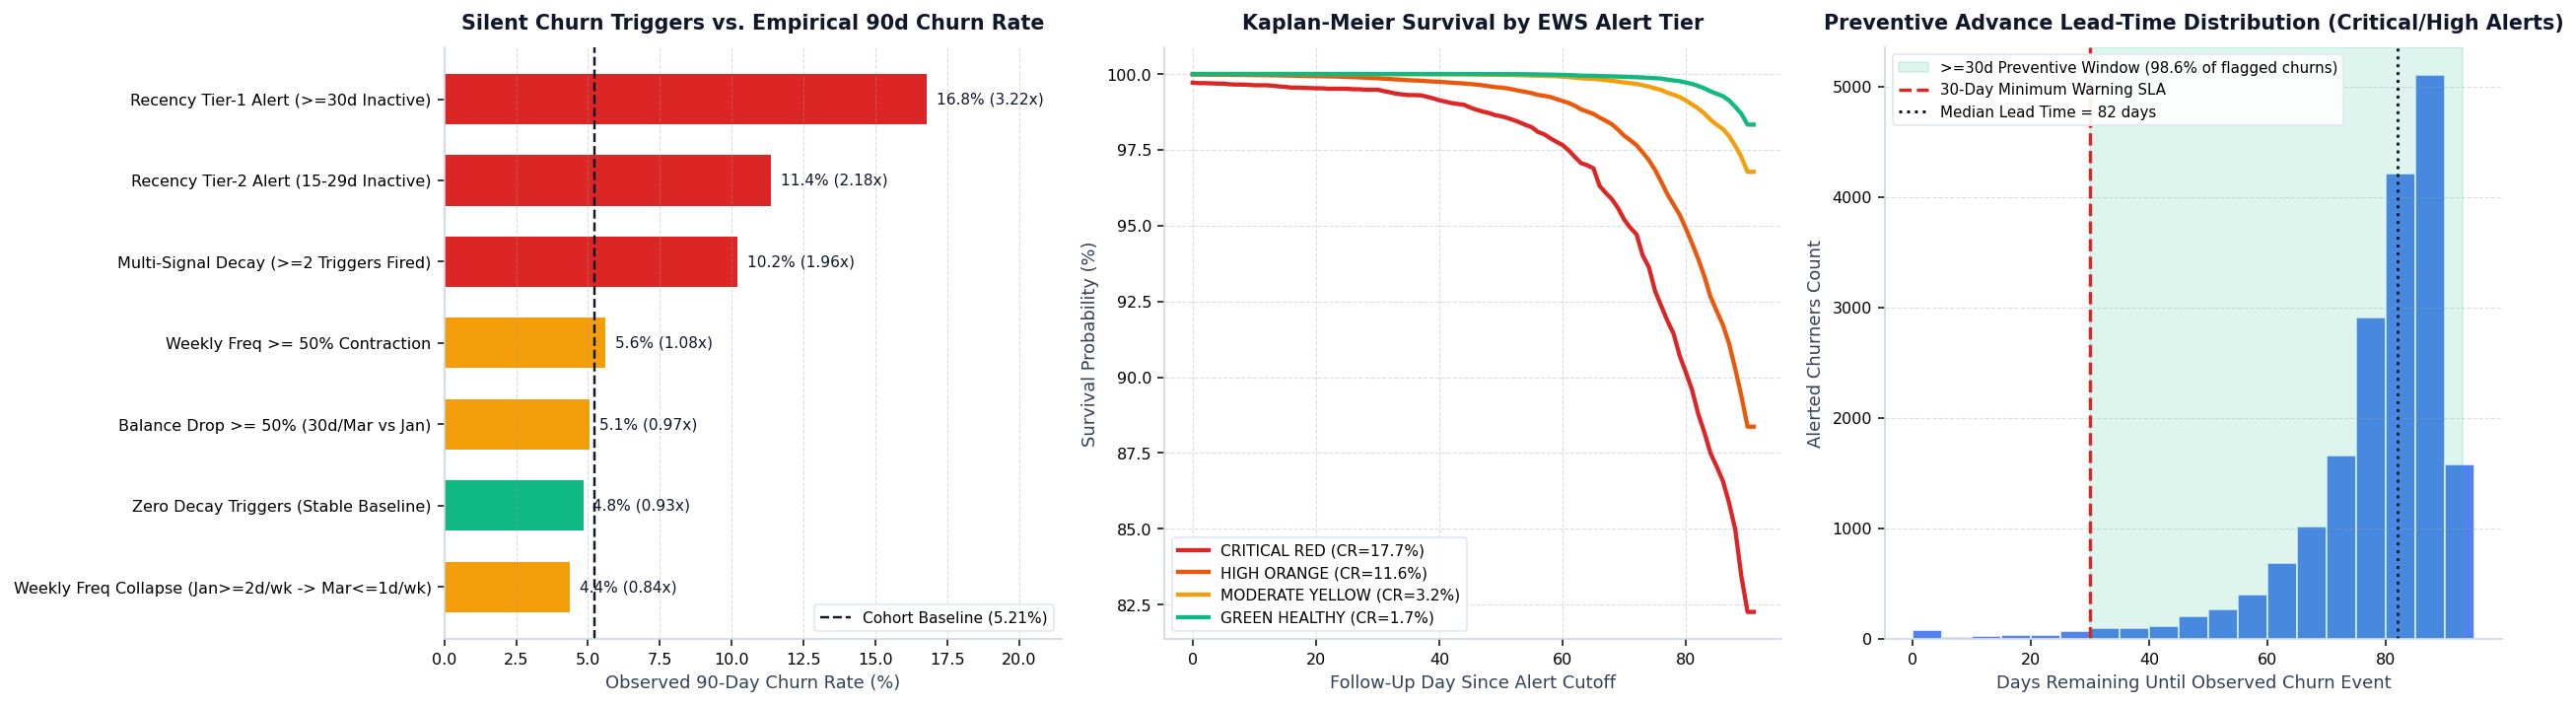

In [9]:
# Preventive Silent Churn EWS thresholds aligned with retention operations SLA
MIN_BASELINE_BAL = 10.0          # Minimum Month-1 average balance required to avoid noise on empty wallets
BAL_DROP_TRIGGER = -0.50         # >= 50% balance decline vs. Month-1 baseline
FREQ_HIGH_WK_MIN = 2.0           # Active baseline cadence threshold (active days / week in Month 1)
FREQ_LOW_WK_MAX = 1.0            # Collapsed Month-3 cadence threshold (active days / week in Month 3)
RECENCY_YELLOW_DAYS = 15         # Tier-2 inactivity alert threshold (days)
RECENCY_RED_DAYS = 30            # Tier-1 severe inactivity alert threshold (days)
ADVANCE_LEAD_SLA_DAYS = 30       # Preventive warning SLA target (days prior to churn event)


def _compute_ews_signals(df_feat: pd.DataFrame, surv_dict: dict, cohort_label: str) -> pd.DataFrame:
    """
    Compute velocity decay indicators, recency escalation flags, composite EWS risk score,
    and operational retention alert levels from behavioral features and ensemble survival curves.
    """
    bal_jan = np.maximum(df_feat["bal_mean_jan"].to_numpy(dtype=np.float64), 0.0)
    bal_mar = np.maximum(df_feat["bal_mean_mar"].to_numpy(dtype=np.float64), 0.0)
    bal_30d = np.maximum(df_feat["bal_mean_30d"].to_numpy(dtype=np.float64), 0.0)

    bal_trend_m3_m1 = (bal_mar - bal_jan) / (bal_jan + 1.0)
    bal_30d_vs_m1_change = (bal_30d - bal_jan) / (bal_jan + 1.0)
    bal_drop_50_flag = ((bal_30d <= 0.50 * bal_jan) | (bal_mar <= 0.50 * bal_jan)) & (bal_jan >= MIN_BASELINE_BAL)

    # Monthly calendar spans inside Q1 2024: Jan=31d (~4.43w), Mar=31d (~4.43w)
    wks_m = 31.0 / 7.0
    jan_act_wk = df_feat["active_days_jan"].to_numpy(dtype=np.float64) / wks_m if "active_days_jan" in df_feat.columns else np.zeros(len(df_feat))
    mar_act_wk = df_feat["active_days_mar"].to_numpy(dtype=np.float64) / wks_m if "active_days_mar" in df_feat.columns else np.zeros(len(df_feat))
    freq_drop_wk = mar_act_wk - jan_act_wk
    freq_half_drop_flag = (mar_act_wk <= 0.50 * jan_act_wk) & (jan_act_wk >= 1.0)
    freq_collapse_flag = (jan_act_wk >= FREQ_HIGH_WK_MIN) & (mar_act_wk <= FREQ_LOW_WK_MAX)

    trx_recency = df_feat["recency_days"].to_numpy(dtype=np.float64)
    recency_15_flag = trx_recency >= RECENCY_YELLOW_DAYS
    recency_30_flag = trx_recency >= RECENCY_RED_DAYS

    s30 = np.asarray(surv_dict[30], dtype=np.float64)
    s60 = np.asarray(surv_dict[60], dtype=np.float64)
    s90 = np.asarray(surv_dict[90], dtype=np.float64)
    p_churn_90 = 1.0 - s90
    p_mid_late_window = np.maximum(s30 - s90, 0.0)  # Forward risk concentrated in days 31..90

    trigger_count = (
        bal_drop_50_flag.astype(int)
        + (freq_half_drop_flag | freq_collapse_flag).astype(int)
        + recency_15_flag.astype(int)
        + recency_30_flag.astype(int)
    )

    # Composite Silent Churn EWS Index [0, 100]: survival ensemble risk weighted by behavioral decay severity
    surv_rank_pct = rankdata(p_churn_90) / max(1, len(p_churn_90))
    decay_severity = np.clip(
        0.35 * np.clip(-bal_trend_m3_m1, 0.0, 1.0)
        + 0.35 * np.clip((jan_act_wk - mar_act_wk) / np.maximum(jan_act_wk, 1.0), 0.0, 1.0)
        + 0.30 * np.clip(trx_recency / 45.0, 0.0, 1.0),
        0.0,
        1.0,
    )
    ews_score = np.round(100.0 * (0.65 * surv_rank_pct + 0.35 * decay_severity), 2)

    alert_level = np.where(
        (ews_score >= 78.0) | ((trigger_count >= 3) & (surv_rank_pct >= 0.65)),
        "CRITICAL RED",
        np.where(
            (ews_score >= 58.0) | ((trigger_count >= 2) & (surv_rank_pct >= 0.45)),
            "HIGH ORANGE",
            np.where(
                (ews_score >= 38.0) | (trigger_count >= 1),
                "MODERATE YELLOW",
                "GREEN HEALTHY",
            ),
        ),
    )

    sla_map = {
        "CRITICAL RED": "Immediate Outbound Retention Call + Fee Waiver (Within 24h)",
        "HIGH ORANGE": "Targeted Cashback / Re-Activation Campaign (Within 72h)",
        "MODERATE YELLOW": "Automated In-App Engagement & BillPay Nudge (Weekly)",
        "GREEN HEALTHY": "Standard Organic Monitoring (No Intervention Cost)",
    }

    rec_tier = np.where(
        trx_recency >= RECENCY_RED_DAYS, "Tier-1 Red (>=30d)",
        np.where(trx_recency >= RECENCY_YELLOW_DAYS, "Tier-2 Yellow (15-29d)",
                 np.where(trx_recency >= 7, "Watchlist (7-14d)", "Active (0-6d)")),
    )

    signal_tags = []
    for bd, fc, r30, r15 in zip(bal_drop_50_flag, (freq_half_drop_flag | freq_collapse_flag), recency_30_flag, recency_15_flag):
        tags = []
        if bd:
            tags.append("BalDrop>=50%")
        if fc:
            tags.append("FreqDrop")
        if r30:
            tags.append("Recency>=30d")
        elif r15:
            tags.append("Recency>=15d")
        signal_tags.append(" + ".join(tags) if tags else "Ensemble Risk Only")

    out_df = pd.DataFrame({
        "ACCOUNT_ID": df_feat["ACCOUNT_ID"].values,
        "Cohort": cohort_label,
        "EWS_Risk_Score": ews_score,
        "Alert_Level": alert_level,
        "TRX_RECENCY_DAYS": trx_recency.astype(int),
        "Recency_Tier": rec_tier,
        "BAL_TREND_M3_M1": np.round(bal_trend_m3_m1, 4),
        "BAL_30D_VS_M1_CHANGE": np.round(bal_30d_vs_m1_change, 4),
        "BAL_DROP_GE_50PCT": bal_drop_50_flag,
        "JAN_ACT_DAYS_WK": np.round(jan_act_wk, 2),
        "MAR_ACT_DAYS_WK": np.round(mar_act_wk, 2),
        "TXN_FREQ_DROP_WK": np.round(freq_drop_wk, 2),
        "TXN_FREQ_COLLAPSE": freq_collapse_flag,
        "TXN_FREQ_HALF_DROP": freq_half_drop_flag,
        "Decay_Trigger_Count": trigger_count,
        "Triggered_Signals": signal_tags,
        "S_30d": np.round(s30, 5),
        "S_60d": np.round(s60, 5),
        "S_90d": np.round(s90, 5),
        "Forward_Hazard_31_90d": np.round(p_mid_late_window, 5),
        "Recommended_SLA": [sla_map[a] for a in alert_level],
    })
    return out_df


ews_train_df = _compute_ews_signals(train, oof_S, "Train (OOF)")
ews_train_df["EVENT_FLAG"] = event
ews_train_df["DURATION_DAYS"] = duration

ews_test_df = _compute_ews_signals(test, test_S, "Holdout (Test)")
ews_test_df.sort_values("EWS_Risk_Score", ascending=False).to_csv(OUTPUT_DIR / "ews_risk_alert_dashboard.csv", index=False)

# 1. Empirical Silent Churn Behavioral Trigger Analysis (Train OOF)
base_cr = float(ews_train_df["EVENT_FLAG"].mean() * 100.0)
trigger_defs = [
    ("Balance Drop >= 50% (30d/Mar vs Jan)", ews_train_df["BAL_DROP_GE_50PCT"]),
    ("Weekly Freq Collapse (Jan>=2d/wk -> Mar<=1d/wk)", ews_train_df["TXN_FREQ_COLLAPSE"]),
    ("Weekly Freq >= 50% Contraction", ews_train_df["TXN_FREQ_HALF_DROP"]),
    ("Recency Tier-2 Alert (15-29d Inactive)", (ews_train_df["TRX_RECENCY_DAYS"] >= 15) & (ews_train_df["TRX_RECENCY_DAYS"] < 30)),
    ("Recency Tier-1 Alert (>=30d Inactive)", ews_train_df["TRX_RECENCY_DAYS"] >= 30),
    ("Multi-Signal Decay (>=2 Triggers Fired)", ews_train_df["Decay_Trigger_Count"] >= 2),
    ("Zero Decay Triggers (Stable Baseline)", ews_train_df["Decay_Trigger_Count"] == 0),
]

trig_rows = []
for t_name, t_mask in trigger_defs:
    sub_t = ews_train_df[t_mask]
    if len(sub_t) == 0:
        continue
    cr_t = float(sub_t["EVENT_FLAG"].mean() * 100.0)
    ev_sub = sub_t[sub_t["EVENT_FLAG"] == 1]
    med_lead = float(ev_sub["DURATION_DAYS"].median()) if len(ev_sub) > 0 else np.nan
    trig_rows.append({
        "Silent Churn Trigger": t_name,
        "Flagged Accounts": int(len(sub_t)),
        "Cohort Share (%)": float(100.0 * len(sub_t) / len(ews_train_df)),
        "Churn Events": int(sub_t["EVENT_FLAG"].sum()),
        "Churn Rate (%)": cr_t,
        "Relative Risk Lift": float(cr_t / max(base_cr, 1e-6)),
        "Hazard / 1k Person-Days": float(1000.0 * sub_t["EVENT_FLAG"].sum() / max(1.0, sub_t["DURATION_DAYS"].sum())),
        "Median Event Day": med_lead,
    })
ews_trigger_df = pd.DataFrame(trig_rows)
ews_trigger_df.to_csv(OUTPUT_DIR / "ews_behavioral_trigger_analysis.csv", index=False)
display_table(
    ews_trigger_df,
    title="Silent Churn Behavioral Trigger Validation (Train OOF Cohort)",
    precision=2,
    max_cols_highlight=["Churn Rate (%)", "Relative Risk Lift", "Hazard / 1k Person-Days"],
)

# 2. Recency Inactivity Tier Breakdown
rec_rows = []
for r_lbl in ["Active (0-6d)", "Watchlist (7-14d)", "Tier-2 Yellow (15-29d)", "Tier-1 Red (>=30d)"]:
    sub_r = ews_train_df[ews_train_df["Recency_Tier"] == r_lbl]
    if len(sub_r) == 0:
        continue
    rec_rows.append({
        "TRX_RECENCY_DAYS Tier": r_lbl,
        "Accounts": int(len(sub_r)),
        "Share (%)": float(100.0 * len(sub_r) / len(ews_train_df)),
        "Churn Events": int(sub_r["EVENT_FLAG"].sum()),
        "Churn Rate (%)": float(sub_r["EVENT_FLAG"].mean() * 100.0),
        "Mean EWS Score": float(sub_r["EWS_Risk_Score"].mean()),
        "Mean S(90d) (%)": float(sub_r["S_90d"].mean() * 100.0),
    })
ews_recency_tier_df = pd.DataFrame(rec_rows)
display_table(
    ews_recency_tier_df,
    title="Real-Time Recency Inactivity Stratification (TRX_RECENCY_DAYS)",
    precision=2,
    max_cols_highlight=["Churn Rate (%)", "Mean EWS Score"],
)

# 3. Preventive 30-Day Advance Lead-Time Backtest Across EWS Alert Tiers
alert_order = ["CRITICAL RED", "HIGH ORANGE", "MODERATE YELLOW", "GREEN HEALTHY"]
val_rows = []
for al in alert_order:
    sub_a = ews_train_df[ews_train_df["Alert_Level"] == al]
    if len(sub_a) == 0:
        continue
    ev_a = sub_a[sub_a["EVENT_FLAG"] == 1]
    adv_30_cnt = int((ev_a["DURATION_DAYS"] >= ADVANCE_LEAD_SLA_DAYS).sum()) if len(ev_a) > 0 else 0
    val_rows.append({
        "EWS Alert Level": al,
        "Train Accounts": int(len(sub_a)),
        "Observed Churns": int(len(ev_a)),
        "Churn Rate (%)": float(sub_a["EVENT_FLAG"].mean() * 100.0),
        "Risk Lift": float((sub_a["EVENT_FLAG"].mean() * 100.0) / max(base_cr, 1e-6)),
        "Median Lead Days": float(ev_a["DURATION_DAYS"].median()) if len(ev_a) > 0 else np.nan,
        "P25 / P75 Lead Days": f"{ev_a['DURATION_DAYS'].quantile(0.25):.0f} / {ev_a['DURATION_DAYS'].quantile(0.75):.0f}" if len(ev_a) > 0 else "-",
        "Captured >=30d Early (%)": float(100.0 * adv_30_cnt / max(1, len(ev_a))) if len(ev_a) > 0 else 0.0,
    })
ews_alert_validation_df = pd.DataFrame(val_rows)
ews_alert_validation_df.to_csv(OUTPUT_DIR / "ews_alert_tier_validation.csv", index=False)
display_table(
    ews_alert_validation_df,
    title="Preventive 30-Day Lead-Time Validation Across EWS Alert Levels",
    precision=2,
    max_cols_highlight=["Churn Rate (%)", "Risk Lift"],
)

# 4. Holdout Real-Time Operational Dashboard Summary & Top 20 Priority Alerts
holdout_summary_rows = []
for al in alert_order:
    sub_h = ews_test_df[ews_test_df["Alert_Level"] == al]
    if len(sub_h) == 0:
        continue
    holdout_summary_rows.append({
        "Alert Level": al,
        "Holdout Accounts": int(len(sub_h)),
        "Share (%)": float(100.0 * len(sub_h) / len(ews_test_df)),
        "Mean EWS Score": float(sub_h["EWS_Risk_Score"].mean()),
        "Mean Predicted 90d Risk (%)": float((1.0 - sub_h["S_90d"]).mean() * 100.0),
        "Mean Recency (Days)": float(sub_h["TRX_RECENCY_DAYS"].mean()),
        "Recommended SLA": sub_h["Recommended_SLA"].iloc[0],
    })
display_table(pd.DataFrame(holdout_summary_rows), title="Holdout Real-Time Risk Alert Queue Distribution", precision=2)

top_ews_watchlist = (
    ews_test_df.sort_values(["EWS_Risk_Score", "Decay_Trigger_Count"], ascending=False)
    .head(20)[[
        "ACCOUNT_ID", "Alert_Level", "EWS_Risk_Score", "TRX_RECENCY_DAYS",
        "BAL_TREND_M3_M1", "JAN_ACT_DAYS_WK", "MAR_ACT_DAYS_WK",
        "S_30d", "S_60d", "S_90d", "Triggered_Signals", "Recommended_SLA",
    ]]
    .reset_index(drop=True)
)
display_table(
    top_ews_watchlist,
    title="Top 20 Holdout Accounts Flagged for Preventive Retention Outreach (Risk Alert Dashboard)",
    precision=3,
    max_cols_highlight=["EWS_Risk_Score"],
)

# Visualization 3: 3-Panel Silent Churn EWS Diagnostic Dashboard
fig_ews, axes_ews = plt.subplots(1, 3, figsize=(19, 5.4))

# Panel 1: Churn Rate Comparison Across Silent Churn Velocity & Recency Triggers
plot_tr = ews_trigger_df.sort_values("Churn Rate (%)", ascending=True)
t_cols = ["#10b981" if "Zero Decay" in lbl else ("#dc2626" if cr >= base_cr * 1.4 else "#f59e0b")
          for lbl, cr in zip(plot_tr["Silent Churn Trigger"], plot_tr["Churn Rate (%)"])]
bars_tr = axes_ews[0].barh(plot_tr["Silent Churn Trigger"], plot_tr["Churn Rate (%)"], color=t_cols, height=0.62)
axes_ews[0].axvline(base_cr, color="#0f172a", linestyle="--", lw=1.3, label=f"Cohort Baseline ({base_cr:.2f}%)")
max_cr = max(plot_tr["Churn Rate (%)"].max(), base_cr)
axes_ews[0].set_xlim(0, max_cr * 1.28)
for b, lft in zip(bars_tr, plot_tr["Relative Risk Lift"]):
    w = b.get_width()
    axes_ews[0].text(w + max_cr * 0.02, b.get_y() + b.get_height() / 2.0, f"{w:.1f}% ({lft:.2f}x)", va="center", fontsize=8.2, color="#0f172a")
_style_ax(axes_ews[0], "Silent Churn Triggers vs. Empirical 90d Churn Rate", "Observed 90-Day Churn Rate (%)", grid_axis="x")
axes_ews[0].legend(loc="lower right", fontsize=8.2)

# Panel 2: Kaplan-Meier Survival Divergence Across EWS Alert Tiers
al_colors = {"GREEN HEALTHY": "#10b981", "MODERATE YELLOW": "#f59e0b", "HIGH ORANGE": "#ea580c", "CRITICAL RED": "#dc2626"}
max_d_ews = int(duration.max())
for al in alert_order:
    sub_a = ews_train_df[ews_train_df["Alert_Level"] == al]
    if len(sub_a) < 5:
        continue
    kt_a = kaplan_meier_table(sub_a["DURATION_DAYS"].values, sub_a["EVENT_FLAG"].values, max_day=max_d_ews)
    axes_ews[1].plot(kt_a["day"], kt_a["survival"] * 100.0, lw=2.3, color=al_colors[al],
                     label=f"{al} (CR={sub_a['EVENT_FLAG'].mean() * 100:.1f}%)")
_style_ax(axes_ews[1], "Kaplan-Meier Survival by EWS Alert Tier", "Follow-Up Day Since Alert Cutoff", "Survival Probability (%)")
axes_ews[1].legend(loc="lower left", fontsize=8.2)

# Panel 3: Preventive Lead-Time Distribution (Days Before Churn Among Critical + High Alerts)
flagged_churners = ews_train_df[(ews_train_df["EVENT_FLAG"] == 1) & (ews_train_df["Alert_Level"].isin(["CRITICAL RED", "HIGH ORANGE"]))]["DURATION_DAYS"].to_numpy()
if len(flagged_churners) == 0:
    flagged_churners = ews_train_df[ews_train_df["EVENT_FLAG"] == 1]["DURATION_DAYS"].to_numpy()
pct_30_early = float((flagged_churners >= ADVANCE_LEAD_SLA_DAYS).mean() * 100.0) if len(flagged_churners) > 0 else 0.0
axes_ews[2].hist(flagged_churners, bins=np.arange(0, max_d_ews + 6, 5), color="#2563eb", alpha=0.80, edgecolor="#ffffff")
axes_ews[2].axvspan(ADVANCE_LEAD_SLA_DAYS, max_d_ews + 2, color="#10b981", alpha=0.14, label=f">=30d Preventive Window ({pct_30_early:.1f}% of flagged churns)")
axes_ews[2].axvline(ADVANCE_LEAD_SLA_DAYS, color="#dc2626", linestyle="--", lw=1.8, label="30-Day Minimum Warning SLA")
if len(flagged_churners) > 0:
    med_l = float(np.median(flagged_churners))
    axes_ews[2].axvline(med_l, color="#0f172a", linestyle=":", lw=1.6, label=f"Median Lead Time = {med_l:.0f} days")
_style_ax(axes_ews[2], "Preventive Advance Lead-Time Distribution (Critical/High Alerts)", "Days Remaining Until Observed Churn Event", "Alerted Churners Count", grid_axis="y")
axes_ews[2].legend(loc="upper left", fontsize=8.0)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ews_silent_churn_dashboard.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig_ews)